# First Practical Work — Choosing and Interpreting the Right Chart, then Learning from Data to Make Decisions
**Dataset:** Pima Indians Diabetes Database (768 patients, 8 attributes, binary target `Outcome`)
**Student:** Begag Younes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import BaggingClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score)
from sklearn.base import clone
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
RS = 42

df = pd.read_csv(r"C:\Users\yunuus\Downloads\diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


**Observation.** The dataset has 768 rows and 9 columns, all numeric, with no `NaN`. However, `describe()` shows a **minimum of 0** for Glucose, BloodPressure, SkinThickness, Insulin and BMI, which is physically impossible: missing values are hidden as zeros (see Q1).

# Part 1 — Understanding the Data

## Question 1 — Attribute description and impossible zeros

The aim of the dataset is to predict whether a patient has diabetes (`Outcome`) from 8 diagnostic measurements.
Units and meanings come from the dataset documentation (they are not stored in the CSV).

| Attribute | Type | Unit | Meaning |
|---|---|---|---|
| Pregnancies | Numeric (discrete) | count | Number of times pregnant |
| Glucose | Numeric (continuous) | mg/dL | Plasma glucose concentration 2 h after an oral glucose tolerance test |
| BloodPressure | Numeric (continuous) | mm Hg | Diastolic blood pressure |
| SkinThickness | Numeric (continuous) | mm | Triceps skin-fold thickness (estimate of body fat) |
| Insulin | Numeric (continuous) | µU/mL | 2-hour serum insulin |
| BMI | Numeric (continuous) | kg/m² | Body mass index = weight / height² |
| DiabetesPedigreeFunction | Numeric (continuous) | score (no unit) | Genetic risk score based on family history |
| Age | Numeric (discrete) | years | Age of the patient (all ≥ 21) |
| Outcome | Categorical (binary) | — | Target: 1 = diabetic, 0 = non-diabetic |

In [4]:
# Columns where a value of 0 is physically impossible
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# (df == 0) gives True/False for each cell; .sum() counts the True values per column
zeros = (df == 0).sum()
print("Number of zeros per column:")
print(zeros)

Number of zeros per column:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


**Answer.**
- **Impossible zeros:** Glucose (5), BloodPressure (35), SkinThickness (227), Insulin (374), BMI (11). A living person cannot have a glucose level, a blood pressure, a skin fold or a BMI equal to 0.
- **What they represent:** **missing values**: the measurement was not taken or not recorded, and "unknown" was encoded as 0.
- Zeros in **Pregnancies** (111) are valid (never pregnant), and zeros in **Outcome** (500) are the negative class: they are not missing values.

## Question 2 — Choosing charts (no code)

**(a) Most appropriate chart for each task**

| Task | Chart |
|---|---|
| Comparing categories | Bar chart |
| Distribution of one numeric variable | Histogram (or box plot / violin / density plot) |
| Relationship between two numeric variables | Scatter plot |
| Trend over an ordered variable | Line chart |
| Parts of a whole | Pie / donut chart (or stacked bar) |
| Correlations among many variables | Heatmap of the correlation matrix (or pair plot) |

**(b) First chart to draw:** small-multiple histograms of all eight attributes. In a single figure they show the range, shape and skewness of every variable, and they immediately expose the spikes at 0 (hidden missing values) that must be handled before any other analysis. A bar chart of `Outcome` comes right after to check class balance.

**(c) Hypothesis:** Glucose should be the best separator (diabetes is defined by high blood glucose), followed by BMI (obesity is a major risk factor), Age, and DiabetesPedigreeFunction (family history). BloodPressure and SkinThickness are expected to be weaker. The following charts will confirm or reject this.

# Part 2 — Class Distribution and Missing Values

## Question 3 — Class distribution of Outcome
- **(a) Chart:** bar chart
- **(b) Task:** comparison (counts of two categories)
- **(c) Why:** bars share a common baseline, so their lengths are compared precisely; a pie chart would force us to compare angles, which the eye judges poorly.

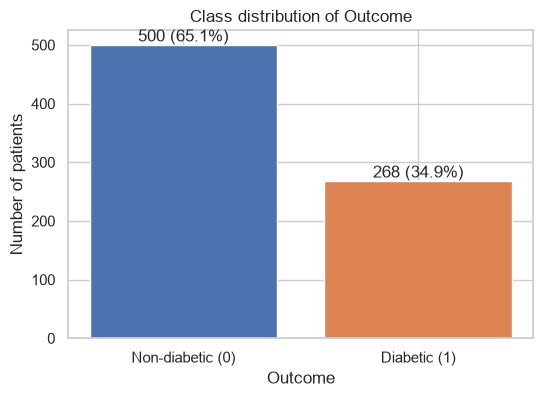

Outcome
0    500
1    268
Name: count, dtype: int64

In [5]:
# Count patients in each class; sort_index() puts class 0 before class 1
counts = df["Outcome"].value_counts().sort_index()
labels = ["Non-diabetic (0)", "Diabetic (1)"]
colors = ["#4C72B0", "#DD8452"]          # blue = non-diabetic, orange = diabetic (reused everywhere)

fig, ax = plt.subplots(figsize=(6, 4))   # one figure, one axis (6×4 inches)
bars = ax.bar(labels, counts.values, color=colors)

# Write "count (percentage)" on top of each bar
ax.bar_label(bars, labels=[f"{c} ({c/len(df):.1%})" for c in counts.values])

ax.set_title("Class distribution of Outcome")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of patients")
plt.show()
counts

**Interpretation.** 500 patients (65.1 %) are non-diabetic and 268 (34.9 %) are diabetic, a ratio of about 1.9 : 1. The dataset is **moderately imbalanced**.

**Why class imbalance matters:**
- A model that always predicts "non-diabetic" already reaches 65 % accuracy while detecting no patient, so accuracy is misleading.
- During training the model is pushed toward the majority class and tends to miss diabetics (low recall), the most dangerous error in medicine.
- We therefore use a **stratified** train/test split and evaluate with precision, recall, F1 and ROC-AUC.

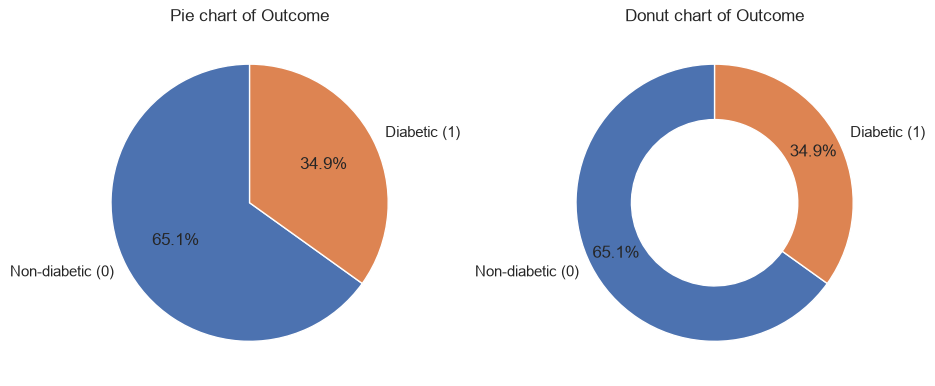

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))   # 1 row, 2 charts side by side

# Pie: autopct writes the percentage in each slice; startangle=90 starts at the top
axes[0].pie(counts, labels=labels, autopct="%1.1f%%", colors=colors, startangle=90)
axes[0].set_title("Pie chart of Outcome")

# Donut = pie with a hole: wedgeprops width=0.4 keeps only the outer ring;
# pctdistance=0.8 places the percentages on the ring
axes[1].pie(counts, labels=labels, autopct="%1.1f%%", colors=colors, startangle=90,
            wedgeprops=dict(width=0.4), pctdistance=0.8)
axes[1].set_title("Donut chart of Outcome")
plt.show()

**Interpretation.** Both charts show that about one third of patients are diabetic, but without the percentage labels it would be hard to tell 30 % from 38 %. The bar chart of Q3 conveys the same message more precisely and also shows absolute counts.

**Limitations of pie and donut charts:**
- Humans compare angles and areas much less accurately than lengths, so small differences between slices are invisible.
- They show no absolute values without labels.
- Comparing several pies side by side is very difficult.
- 3D or exploded effects distort the slices.
- A donut removes the centre, so the reader must judge arc lengths, which is even less precise.

**When to avoid them:** more than ~4–5 categories, slices of similar size, when precise comparison is needed, or when several distributions must be compared. A bar chart is better in all these cases.

## Question 5 — Visualising missing values
First, the impossible zeros are replaced by `NaN`. Two charts are compared:
- **Bar chart** of missing counts per attribute. **Task:** comparison. **Why:** exact, sorted counts.
- **Heatmap** of the missing-value matrix. **Task:** pattern of missingness. **Why:** shows *where* values are missing and whether they co-occur in the same patients.

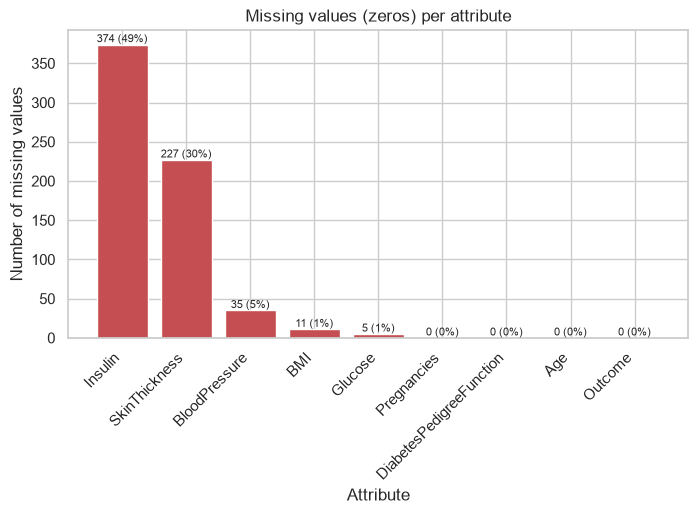

In [7]:
# Copy the data and replace impossible zeros with NaN (= real missing value)
df_nan = df.copy()                                   # copy() keeps the original df unchanged
df_nan[zero_cols] = df_nan[zero_cols].replace(0, np.nan)

# Count NaN per column, largest first
missing = df_nan.isna().sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(missing.index, missing.values, color="#C44E52")
# Label each bar with "count (percentage of patients)"
ax.bar_label(bars, labels=[f"{m} ({m/len(df):.0%})" for m in missing.values], fontsize=8)
ax.set_title("Missing values (zeros) per attribute")
ax.set_xlabel("Attribute")
ax.set_ylabel("Number of missing values")
plt.xticks(rotation=45, ha="right")                 # rotate long names so they don't overlap
plt.show()

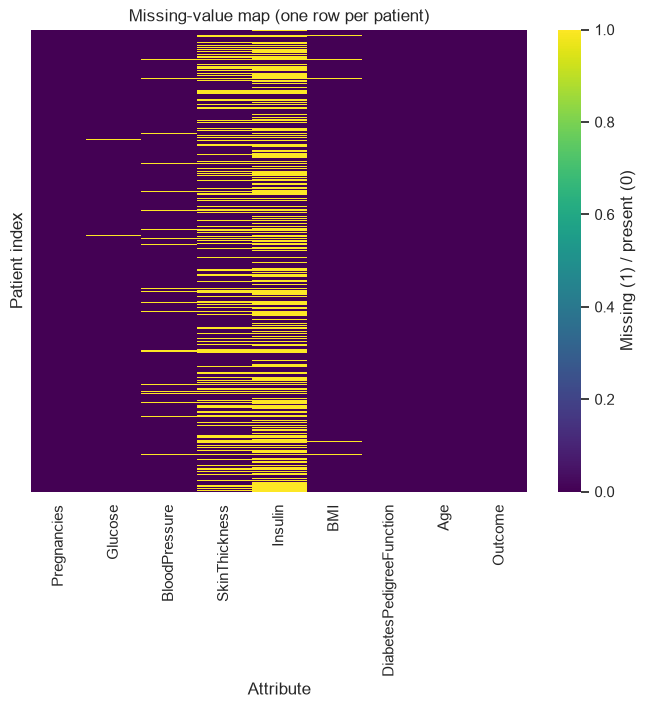

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
# df_nan.isna() is a True/False matrix (768 patients × 9 columns);
# the heatmap colours each cell: one colour = missing, the other = present
sns.heatmap(df_nan.isna(), cmap="viridis", yticklabels=False, ax=ax,
            cbar_kws={"label": "Missing (1) / present (0)"})
ax.set_title("Missing-value map (one row per patient)")
ax.set_xlabel("Attribute")
ax.set_ylabel("Patient index")
plt.show()

**Interpretation.** **Insulin** has the most missing values (374, 49 % of patients), followed by SkinThickness (227, 30 %). BloodPressure (35), BMI (11) and Glucose (5) are almost complete.

**Which chart is clearer?** The **bar chart** is clearer for this task: it gives exact, sorted counts that are read instantly. The heatmap is hard to read with 768 rows, but it reveals something the bar chart hides: when SkinThickness is missing, Insulin is almost always missing too, so these values are not missing completely at random.

## Question 6 — Imputation
The zeros are already replaced by `NaN` (`df_nan`). Two imputed datasets are built:

**(a) `df_median`:** continuous attributes are filled with the **median**, discrete attributes with the **mode**. The 5 affected attributes are continuous physical measurements, so they get the median, which is robust to the strong skew and outliers (unlike the mean). Discrete attributes (Pregnancies, Age) have no missing values; the code handles them with the mode for completeness.

**(b) `df_knn`:** `KNNImputer` fills each missing value with the distance-weighted average of the *k* most similar patients.
- **Scaling first** is mandatory: KNN uses Euclidean distance, and without scaling Insulin (range 14–846) would dominate DiabetesPedigreeFunction (range 0.08–2.4).
- **Choice of k = 5:** small enough to stay local (neighbours are truly similar patients), large enough to average out noise; odd, and the scikit-learn default. A large k (e.g. √768 ≈ 28) would pull every value toward the global mean, which is what median imputation already does.
- `Outcome` is **not** given to the imputer, to avoid leaking the target into the features.

In [9]:
features = df.columns.drop("Outcome")   # the 8 input attributes (everything except the target)

# ---------- (a) Median / mode imputation ----------
continuous = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
discrete = ["Pregnancies", "Age"]

df_median = df_nan.copy()
for col in continuous:
    # replace each NaN with the column median
    df_median[col] = df_median[col].fillna(df_median[col].median())
for col in discrete:
    # mode() returns the most frequent value(s); [0] takes the first
    df_median[col] = df_median[col].fillna(df_median[col].mode()[0])

# ---------- (b) KNN imputation ----------
# 1) Scale: mean 0, std 1 for every attribute (NaN are ignored when fitting)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_nan[features])

# 2) Impute: each NaN = weighted mean of the 5 nearest patients
#    (weights="distance" → closer neighbours count more)
imputer = KNNImputer(n_neighbors=5, weights="distance")
X_imputed = imputer.fit_transform(X_scaled)

# 3) Unscale: back to the original units (mg/dL, kg/m², ...)
df_knn = pd.DataFrame(scaler.inverse_transform(X_imputed), columns=features)
df_knn["Outcome"] = df["Outcome"].values            # add the target back (not used for imputation)

# Check: no NaN should remain
print("Remaining NaN — df_median:", df_median.isna().sum().sum(), "| df_knn:", df_knn.isna().sum().sum())

Remaining NaN — df_median: 0 | df_knn: 0


**Comparing the imputations on Insulin**
- **(a) Chart:** small multiples, 3 histograms (original / median / KNN) stacked on a shared x-axis
- **(b) Task:** distribution (comparison of shapes)
- **(c) Why:** the shared x-axis lets us compare the shapes directly; overlaying three histograms on one axis would make them hide each other.

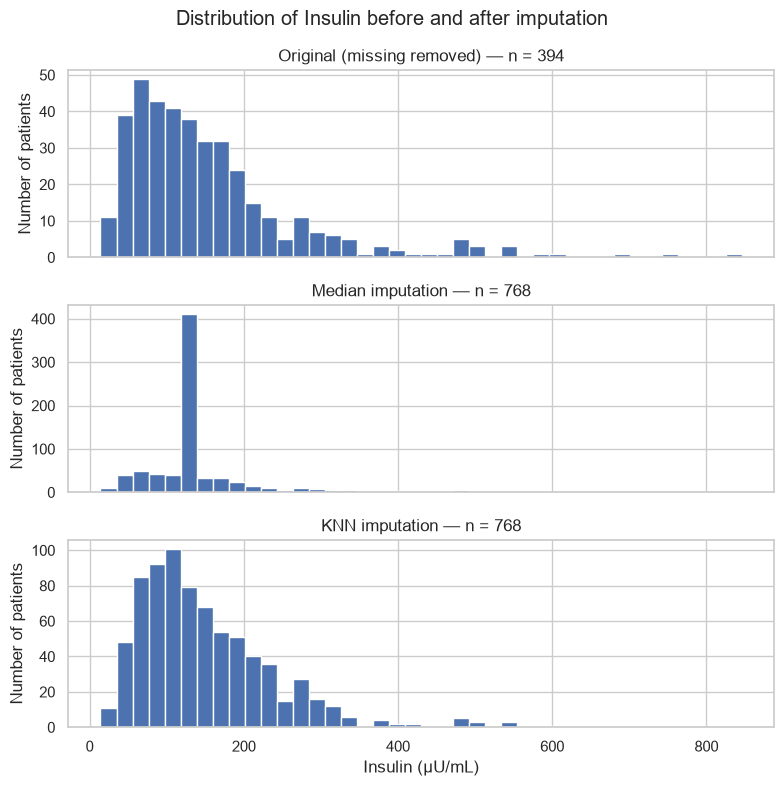

,Original (missing removed),Median imputation,KNN imputation
mean,155.55,140.67,153.73
median,125.00,125.00,130.00
std,118.78,86.38,98.04
skewness,2.17,3.38,2.13


In [10]:
var = "Insulin"
# Three versions of the same column: original (NaN removed), after median, after KNN
versions = [df_nan[var].dropna(), df_median[var], df_knn[var]]
names = ["Original (missing removed)", "Median imputation", "KNN imputation"]

# 3 rows, 1 column; sharex=True → same x-axis on every panel
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
for ax, data, name in zip(axes, versions, names):     # zip loops over the 3 lists together
    ax.hist(data, bins=40, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{name} — n = {len(data)}")
    ax.set_ylabel("Number of patients")
axes[-1].set_xlabel("Insulin (µU/mL)")                # x label only on the bottom panel
fig.suptitle("Distribution of Insulin before and after imputation")
plt.tight_layout()                                    # avoid overlapping titles and labels
plt.show()

# Summary statistics to compare the three versions numerically
pd.DataFrame({n: [d.mean(), d.median(), d.std(), d.skew()] for n, d in zip(names, versions)},
             index=["mean", "median", "std", "skewness"]).round(2)

**Interpretation.** Median imputation assigns the single value 125 µU/mL to 374 patients (almost half), which creates a huge artificial spike: the standard deviation falls from 118.8 to 86.4 and the skewness jumps from 2.17 to 3.38. KNN imputation spreads the imputed values according to similar patients, so its standard deviation (98.0) and skewness (2.13) stay close to the original.

→ **KNN imputation better preserves the original shape of the distribution.** Both datasets are reused in Part 5.

# Part 3 — Exploring Distributions and Relationships
All charts in this part use `df_median` unless stated otherwise.

## Question 7 — Distribution of Glucose
- **(a) Chart:** histogram
- **(b) Task:** distribution of one numeric variable
- **(c) Why:** it shows shape, centre, spread and skewness at once; a box plot would hide the shape (peaks, gaps).

Three bin widths are tested: **1 mg/dL** (too narrow), **10 mg/dL** (reasonable) and **50 mg/dL** (too wide).

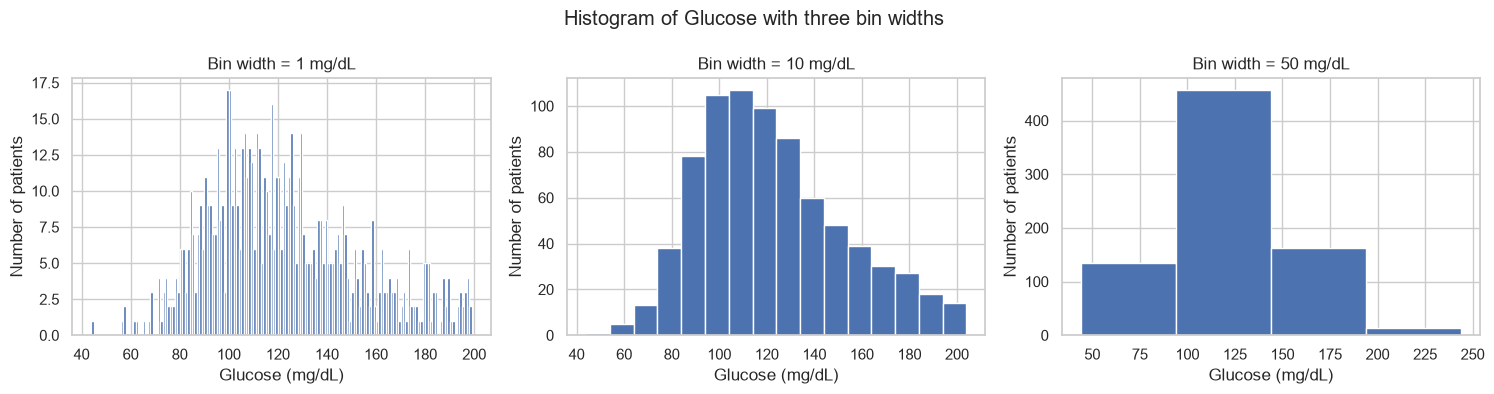

mean = 121.7 | median = 117.0 | std = 30.4 | IQR = 40.5 | skewness = 0.54 | min = 44.0 | max = 199.0


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))      # 3 histograms side by side
for ax, bw in zip(axes, [1, 10, 50]):                 # bw = bin width in mg/dL
    # bin edges: min, min+bw, min+2bw, ... up to max
    bins = np.arange(df_median["Glucose"].min(), df_median["Glucose"].max() + bw, bw)
    ax.hist(df_median["Glucose"], bins=bins, color="#4C72B0", edgecolor="white")
    ax.set_title(f"Bin width = {bw} mg/dL")
    ax.set_xlabel("Glucose (mg/dL)")
    ax.set_ylabel("Number of patients")
fig.suptitle("Histogram of Glucose with three bin widths")
plt.tight_layout()
plt.show()

# Numbers describing centre (mean, median), spread (std, IQR) and skewness
g = df_median["Glucose"]
print(f"mean = {g.mean():.1f} | median = {g.median():.1f} | std = {g.std():.1f} | "
      f"IQR = {g.quantile(.75) - g.quantile(.25):.1f} | skewness = {g.skew():.2f} | "
      f"min = {g.min()} | max = {g.max()}")
# skewness > 0 → long tail on the right ; skewness < 0 → long tail on the left

**Choice of bin width.** With 1 mg/dL bins the histogram is noisy (random spikes, many empty bins); with 50 mg/dL bins only 4 bars remain and the shape disappears. **I keep 10 mg/dL**, which gives a smooth but detailed shape (close to the Freedman–Diaconis rule).

**Description.**
- **Shape:** unimodal (one peak).
- **Centre:** median = 117 mg/dL, mean = 121.7 mg/dL.
- **Spread:** standard deviation = 30.4 mg/dL, IQR = 40.5 mg/dL, range 44–199 mg/dL.
- **Skewness:** slightly **right-skewed** (0.54); mean > median confirms it. The right tail corresponds to hyperglycaemic patients.

## Question 8 — Distributions of all eight attributes
- **(a) Chart:** small multiples, a 2 × 4 grid of histograms with density curves, one panel per attribute
- **(b) Task:** distribution
- **(c) Why:** the same style in one figure lets us compare all distributions at a glance. Eight separate figures force the reader to scroll and remember, and one overlaid figure is unreadable because the attributes have completely different units and ranges.

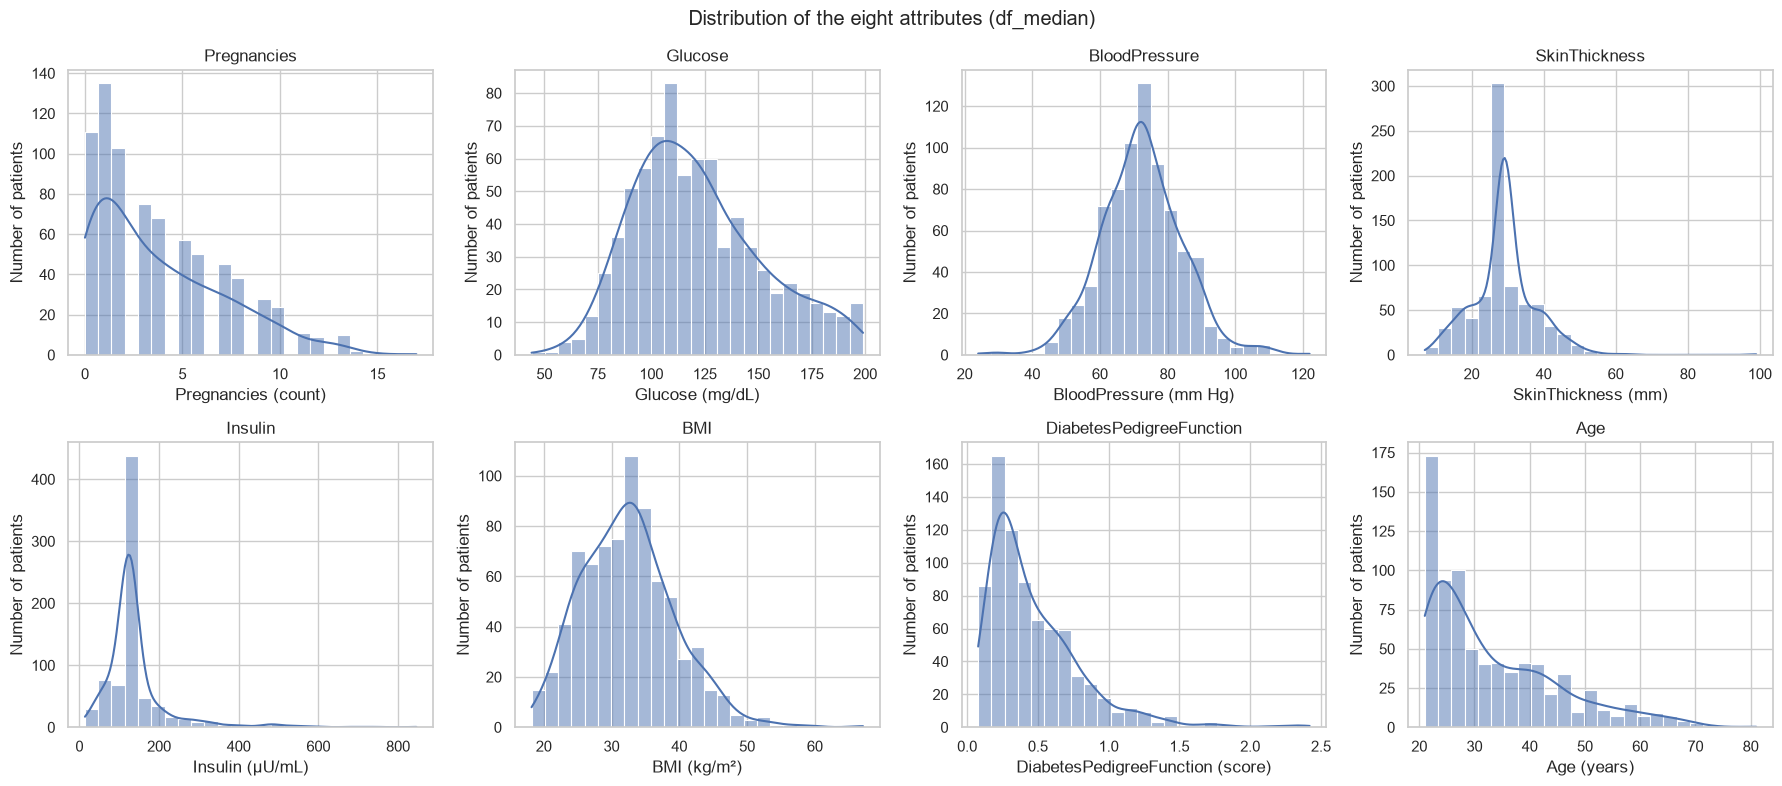

Insulin                     3.38
DiabetesPedigreeFunction    1.92
Age                         1.13
Pregnancies                 0.90
SkinThickness               0.84
BMI                         0.60
Glucose                     0.54
BloodPressure               0.14
dtype: float64

In [12]:
# Unit of each attribute, used to label the x-axes (reused in later questions)
units = {"Pregnancies": "count", "Glucose": "mg/dL", "BloodPressure": "mm Hg",
         "SkinThickness": "mm", "Insulin": "µU/mL", "BMI": "kg/m²",
         "DiabetesPedigreeFunction": "score", "Age": "years"}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))       # grid of 2 × 4 = 8 panels
for ax, col in zip(axes.flat, features):              # axes.flat turns the grid into a simple list
    # histogram + smooth density curve (kde=True)
    sns.histplot(df_median[col], bins=25, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_xlabel(f"{col} ({units[col]})")
    ax.set_ylabel("Number of patients")
fig.suptitle("Distribution of the eight attributes (df_median)")
plt.tight_layout()
plt.show()

# Skewness of each attribute, from most right-skewed to least
df_median[features].skew().sort_values(ascending=False).round(2)

**Advantage of small multiples:** one consistent figure in which every panel uses the same style, so differences in shape stand out immediately, without scrolling between figures or untangling overlapping curves of incompatible scales.

**Skewness.** All attributes are **right-skewed** (positive skewness); none is left-skewed.
- **Strongly right-skewed:** Insulin (3.38), DiabetesPedigreeFunction (1.92), Age (1.13; most patients are 21–30).
- **Moderately right-skewed:** Pregnancies (0.90), SkinThickness (0.84), BMI (0.60), Glucose (0.54).
- **Almost symmetric:** BloodPressure (0.14).

The tall spikes on SkinThickness and Insulin are an artefact of median imputation.

## Question 9 — Box plots by Outcome
- **(a) Chart:** box plot, one per attribute, split by Outcome
- **(b) Task:** distribution (comparison between two groups)
- **(c) Why:** a compact summary of median, spread and outliers, ideal for comparing two groups side by side; two overlaid histograms would hide each other.

**Elements of a box plot**
| Element | Meaning |
|---|---|
| Line inside the box | **Median** (Q2): 50 % of values are below |
| Bottom of the box | **Q1**: 25th percentile |
| Top of the box | **Q3**: 75th percentile |
| Box height | **IQR** = Q3 − Q1 (middle 50 % of the data) |
| Whiskers | Extend to the furthest value within [Q1 − 1.5·IQR, Q3 + 1.5·IQR] |
| Isolated points | **Outliers** (beyond the whiskers, 1.5×IQR rule) |

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, features):
    # x = class, y = attribute → one box per class; hue + palette colour the boxes
    sns.boxplot(data=df_median, x="Outcome", y=col, hue="Outcome",
                palette=colors, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Outcome (0 = non-diabetic, 1 = diabetic)")
    ax.set_ylabel(f"{col} ({units[col]})")
fig.suptitle("Box plots of each attribute by Outcome")
plt.tight_layout()
plt.show()

# Median of each attribute per class (quantifies the differences seen on the chart)
df_median.groupby("Outcome")[list(features)].median().T

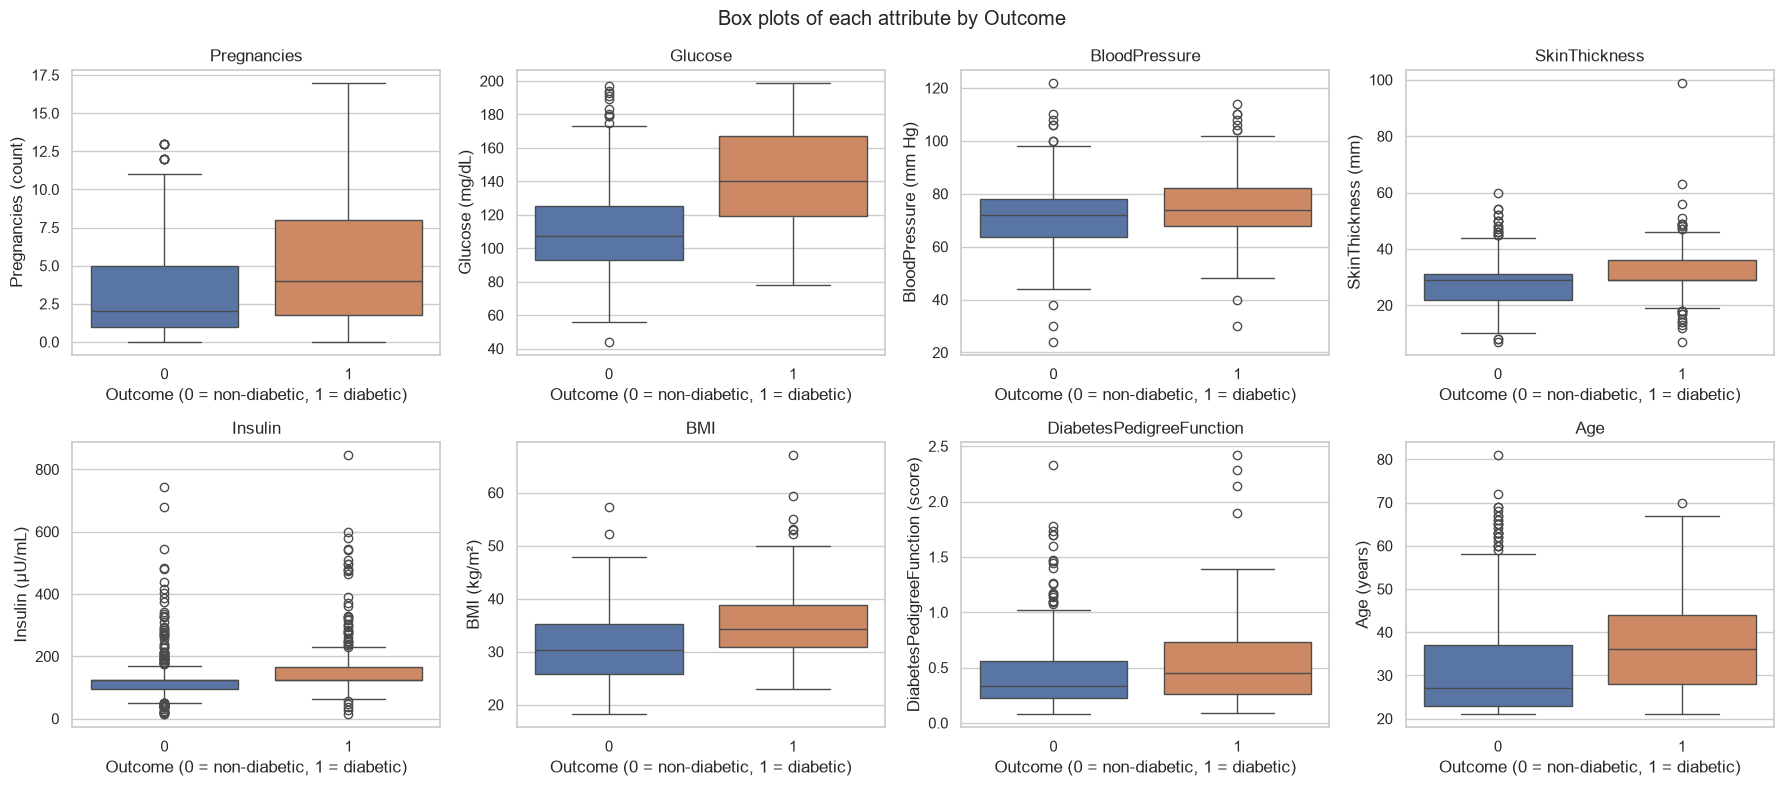

Outcome,0,1
Pregnancies,2.000,4.000
Glucose,107.500,140.000
BloodPressure,72.000,74.000
SkinThickness,29.000,29.000
Insulin,125.000,125.000
BMI,30.400,34.250
DiabetesPedigreeFunction,0.336,0.449
Age,27.000,36.000


In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, features):
    # x = class, y = attribute → one box per class; hue + palette colour the boxes
    sns.boxplot(data=df_median, x="Outcome", y=col, hue="Outcome",
                palette=colors, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Outcome (0 = non-diabetic, 1 = diabetic)")
    ax.set_ylabel(f"{col} ({units[col]})")
fig.suptitle("Box plots of each attribute by Outcome")
plt.tight_layout()
plt.show()

# Median of each attribute per class (quantifies the differences seen on the chart)
df_median.groupby("Outcome")[list(features)].median().T

In [14]:
def iqr_outliers(s):
    """Apply the 1.5×IQR rule to a column and return its key values."""
    q1, q3 = s.quantile([0.25, 0.75])            # 25th and 75th percentiles
    iqr = q3 - q1                                # interquartile range
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr   # fences: values outside them are outliers
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "upper fence": high,
                      "n_outliers": ((s < low) | (s > high)).sum()})   # | means "or"

# Compare the rule on the imputed column and on the real (observed) values only
pd.DataFrame({"df_median": iqr_outliers(df_median["Insulin"]),
              "observed values only": iqr_outliers(df_nan["Insulin"].dropna())}).round(2)

,df_median,observed values only
Q1,121.50,76.25
Q3,127.25,190.00
IQR,5.75,113.75
upper fence,135.88,360.62
n_outliers,346.00,24.00


**Interpretation.** The largest differences between classes are for:
- **Glucose:** median 107.5 vs 140 mg/dL; the boxes barely overlap.
- **Age:** 27 vs 36 years.
- **BMI:** 30.4 vs 34.3 kg/m².
- **Pregnancies:** 2 vs 4.

BloodPressure, SkinThickness and Insulin have almost identical medians in both classes.

**Insulin outliers (1.5×IQR rule).** On the 394 observed values: Q1 = 76.25, Q3 = 190, IQR = 113.75, upper fence = 360.6 → **24 outliers**.
On `df_median` the rule reports 346 "outliers", but this is an artefact: half of the column equals 125, so Q1 = 121.5 and Q3 = 127.25 give an IQR of only 5.75. This again shows how median imputation distorts the distribution.

## Question 10 — Violin plots
- **(a) Chart:** violin plot (Glucose, BMI, Age by Outcome)
- **(b) Task:** distribution (comparison between groups)
- **(c) Why:** it contains the information of a box plot (quartiles drawn inside) plus the full shape of the distribution.

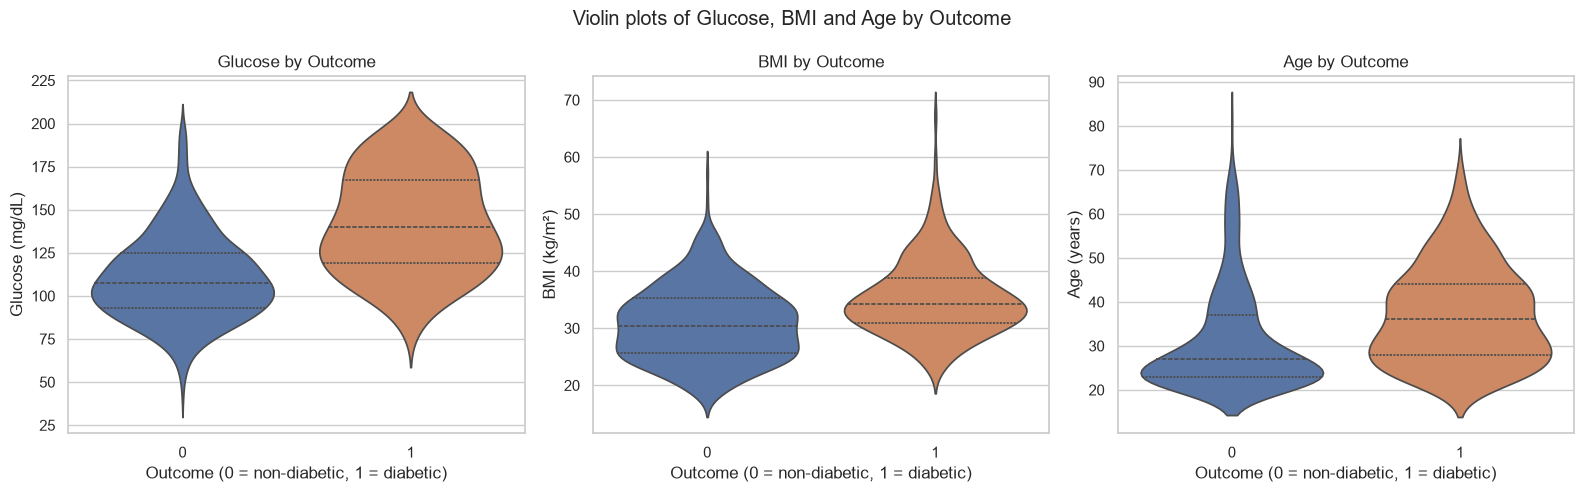

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    # violin = mirrored density curve; inner="quartile" draws Q1, median, Q3 as dashed lines
    sns.violinplot(data=df_median, x="Outcome", y=col, hue="Outcome", palette=colors,
                   inner="quartile", legend=False, ax=ax)
    ax.set_title(f"{col} by Outcome")
    ax.set_xlabel("Outcome (0 = non-diabetic, 1 = diabetic)")
    ax.set_ylabel(f"{col} ({units[col]})")
fig.suptitle("Violin plots of Glucose, BMI and Age by Outcome")
plt.tight_layout()
plt.show()

**Interpretation.** The diabetic Glucose violin is shifted upward and wider, while non-diabetics concentrate around 100 mg/dL. For Age, non-diabetics form a very narrow bulge at 21–30 years, whereas diabetics are spread between 25 and 60: a difference in *shape* that the box plot only partly shows. BMI is shifted upward for diabetics, with similar shapes.

**What a violin shows that a box plot hides:** the full density, including multiple peaks (multimodality), where the values concentrate, gaps, and the exact shape of the tails.

**Which to prefer:**
- **Box plot:** many groups, small samples (the density estimate becomes unreliable), a non-technical audience, or when explicit outliers matter.
- **Violin plot:** enough data, and the shape of the distribution matters.

## Question 11 — Density plot of Glucose by class
- **(a) Chart:** kernel density estimate (KDE), one curve per class on the same axes
- **(b) Task:** distribution (comparison between groups)
- **(c) Why:** smooth curves overlap cleanly. Two overlaid histograms hide each other, depend on the bin choice, and have different heights because the classes have different sizes (here each curve is normalised separately with `common_norm=False`).

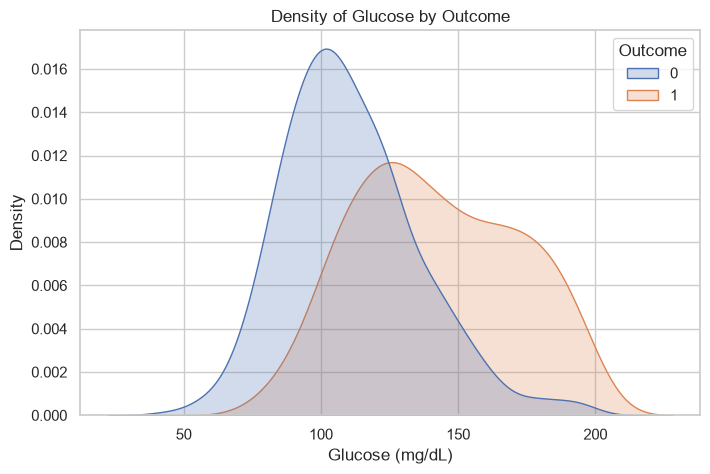

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
# One density curve per class; common_norm=False → each curve has area 1,
# so the smaller (diabetic) class is not squashed
sns.kdeplot(data=df_median, x="Glucose", hue="Outcome", fill=True, common_norm=False,
            palette=colors, ax=ax)
ax.set_title("Density of Glucose by Outcome")
ax.set_xlabel("Glucose (mg/dL)")
ax.set_ylabel("Density")
plt.show()

In [17]:
from scipy.stats import gaussian_kde

xs = np.linspace(40, 200, 1601)    # glucose values from 40 to 200 (step 0.1)

# Estimate the density of each class and evaluate it at every value of xs
k0 = gaussian_kde(df_median.loc[df_median.Outcome == 0, "Glucose"])(xs)   # non-diabetic
k1 = gaussian_kde(df_median.loc[df_median.Outcome == 1, "Glucose"])(xs)   # diabetic
p1 = df_median["Outcome"].mean()   # share of diabetics (≈ 0.35)

# First value above 100 where the diabetic curve is higher than the non-diabetic one
print("Density curves cross at   :", round(xs[(xs > 100) & (k1 > k0)][0], 1), "mg/dL")
# Same, weighting each curve by its class size → where diabetics become the majority
print("Diabetics become majority :", round(xs[(xs > 100) & (k1 * p1 > k0 * (1 - p1))][0], 1), "mg/dL")

Density curves cross at   : 124.6 mg/dL
Diabetics become majority : 145.3 mg/dL


**Interpretation.** The non-diabetic curve peaks around 100 mg/dL; the diabetic curve is flatter and centred around 140 mg/dL. The two curves cross at about **125 mg/dL**: above this value a glucose level is more typical of diabetics than of non-diabetics, so **diabetes becomes more frequent above ≈ 125 mg/dL**. Since only 35 % of patients are diabetic, diabetics actually become the **majority above ≈ 145 mg/dL**, consistent with the clinical threshold of 140 mg/dL (2-hour OGTT).

## Question 12 — Relationship between Glucose and BMI
- **(a) Chart:** scatter plot, coloured by Outcome
- **(b) Task:** relationship between two numeric variables
- **(c) Why:** each point is a patient, so we see both the joint distribution and the class pattern; a line chart would impose an order between patients that does not exist.

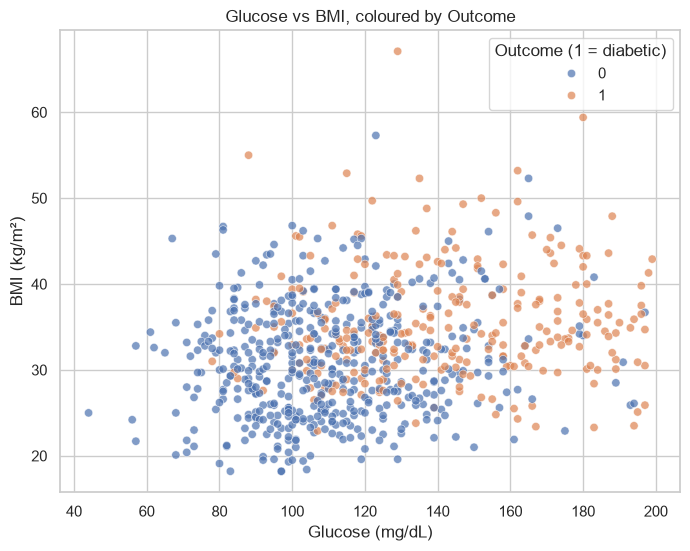

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))
# Each point = one patient; hue colours by class; alpha=0.7 = transparency for overlapping points
sns.scatterplot(data=df_median, x="Glucose", y="BMI", hue="Outcome",
                palette=colors, alpha=0.7, ax=ax)
ax.set_title("Glucose vs BMI, coloured by Outcome")
ax.set_xlabel("Glucose (mg/dL)")
ax.set_ylabel("BMI (kg/m²)")
ax.legend(title="Outcome (1 = diabetic)")
plt.show()

**Interpretation.** Diabetic patients concentrate in the upper-right region (high glucose and BMI above ~30), and non-diabetics in the lower-left, but the two clouds overlap strongly in the middle (glucose 110–150 mg/dL).
- **Distinct groups?** No. There is a trend, not a clear separation.
- **One straight line?** No line can separate them perfectly. A line (mostly a glucose threshold slightly tilted by BMI) would separate them only partially, with many errors on both sides.

## Question 13 — Percentage of diabetic patients per age band
Patients are grouped into 5 age bands: 21–30, 31–40, 41–50, 51–60, 60+.
- **(a) Chart:** bar chart
- **(b) Task:** comparison across ordered categories (trend)
- **(c) Why bar rather than line:** the x-axis is **ordered**, so a line chart could show the trend. But the bands are discrete groups with unequal widths (60+ is open-ended) and very different sizes, and a line would suggest values *between* bands that do not exist. Bars present each band as an independent proportion while the order still makes the trend visible. (A line chart suits a continuous ordered axis such as time; for **unordered** categories only a bar chart is valid.)

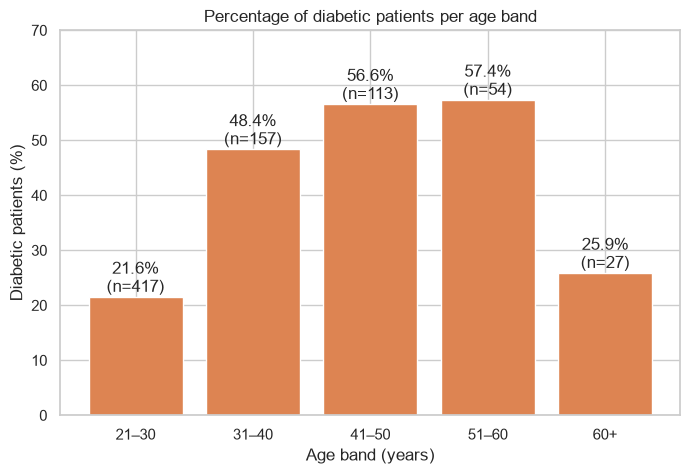

In [19]:
# Band edges: (20,30], (30,40], (40,50], (50,60], (60, ∞)
bins = [20, 30, 40, 50, 60, np.inf]
age_labels = ["21–30", "31–40", "41–50", "51–60", "60+"]
# pd.cut assigns each patient to a band → new categorical column
df_median["AgeBand"] = pd.cut(df_median["Age"], bins=bins, labels=age_labels)

# Mean of Outcome (0/1) in each band = proportion of diabetics; × 100 → percentage
rate = df_median.groupby("AgeBand", observed=True)["Outcome"].mean() * 100
n = df_median["AgeBand"].value_counts().sort_index()   # number of patients per band

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rate.index.astype(str), rate.values, color="#DD8452")
# Label: percentage + sample size (\n = new line)
ax.bar_label(bars, labels=[f"{r:.1f}%\n(n={c})" for r, c in zip(rate.values, n.values)])
ax.set_title("Percentage of diabetic patients per age band")
ax.set_xlabel("Age band (years)")
ax.set_ylabel("Diabetic patients (%)")
ax.set_ylim(0, 70)              # leave room above the bars for the labels
plt.show()

**Interpretation.** The diabetes rate more than doubles from 21–30 (21.6 %) to 31–40 (48.4 %), then keeps rising to 56.6 % (41–50) and 57.4 % (51–60): **the risk increases strongly with age**. The drop to 25.9 % for 60+ must be read with caution: it rests on only 27 patients (high uncertainty) and may reflect a survivor effect.

*Note: `AgeBand` is a new categorical column used only for charts. It is not part of `features`, so it will not enter the models.*

## Question 14 — Mean of each attribute by Outcome
- **(a) Chart:** grouped bar chart (2 bars per attribute, one per class)
- **(b) Task:** comparison (2 groups × 8 attributes)
- **(c) Why:** bars side by side make the gap between classes visible for each attribute.

**Why standardise first?** The attributes have different units and scales (Insulin ≈ 150 µU/mL, DiabetesPedigreeFunction ≈ 0.5). On raw values the bar height would reflect the unit, not the effect: Insulin would dwarf everything and DPF would be invisible. After z-score standardisation, z = (x − mean) / std, every attribute is measured in "standard deviations from the overall mean", so gaps become comparable across attributes.

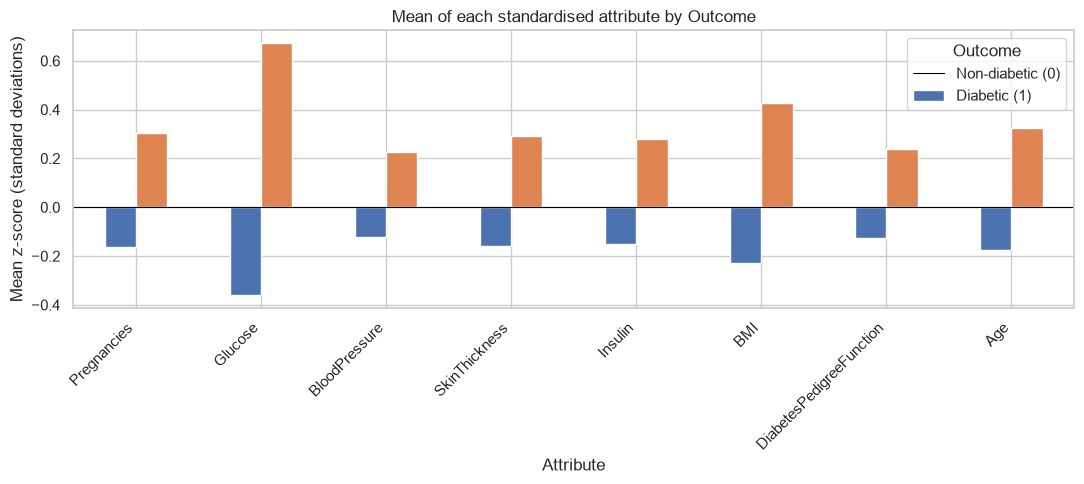

Outcome,0,1
Pregnancies,-0.16,0.30
Glucose,-0.36,0.67
BloodPressure,-0.12,0.23
SkinThickness,-0.16,0.29
Insulin,-0.15,0.28
BMI,-0.23,0.43
DiabetesPedigreeFunction,-0.13,0.24
Age,-0.17,0.33


In [20]:
# Standardise each attribute: z = (x - mean) / std
z = df_median[features].apply(lambda c: (c - c.mean()) / c.std())
z["Outcome"] = df_median["Outcome"]

# Mean z-score per class; .T → one row per attribute (one group of bars each)
means = z.groupby("Outcome").mean().T

ax = means.plot(kind="bar", figsize=(11, 5), color=colors)   # pandas draws the grouped bars
ax.set_title("Mean of each standardised attribute by Outcome")
ax.set_xlabel("Attribute")
ax.set_ylabel("Mean z-score (standard deviations)")
ax.axhline(0, color="black", lw=0.8)        # reference line = overall mean
ax.legend(["Non-diabetic (0)", "Diabetic (1)"], title="Outcome")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
means.round(2)

**Interpretation.** Diabetic patients are above the overall mean on every attribute, and non-diabetics below it. The largest gap is **Glucose** (+0.67 vs −0.36 SD, about 1 standard deviation apart), followed by **BMI** (+0.43 vs −0.23) and **Age** (+0.33 vs −0.17). BloodPressure and DiabetesPedigreeFunction show the smallest gaps. This confirms the hypothesis of Q2(c).

## Question 15 — Correlation matrix
- **(a) Chart:** heatmap of the correlation matrix
- **(b) Task:** relationship among many variables
- **(c) Why:** 81 coefficients are read at a glance through colour; a table of numbers or 36 separate scatter plots would be much slower to scan.

**Coefficient used:** Pearson's *r* (linear correlation, from −1 to +1). Spearman's ρ (rank-based) would be more robust to the skewed variables; it gives a similar ranking here.

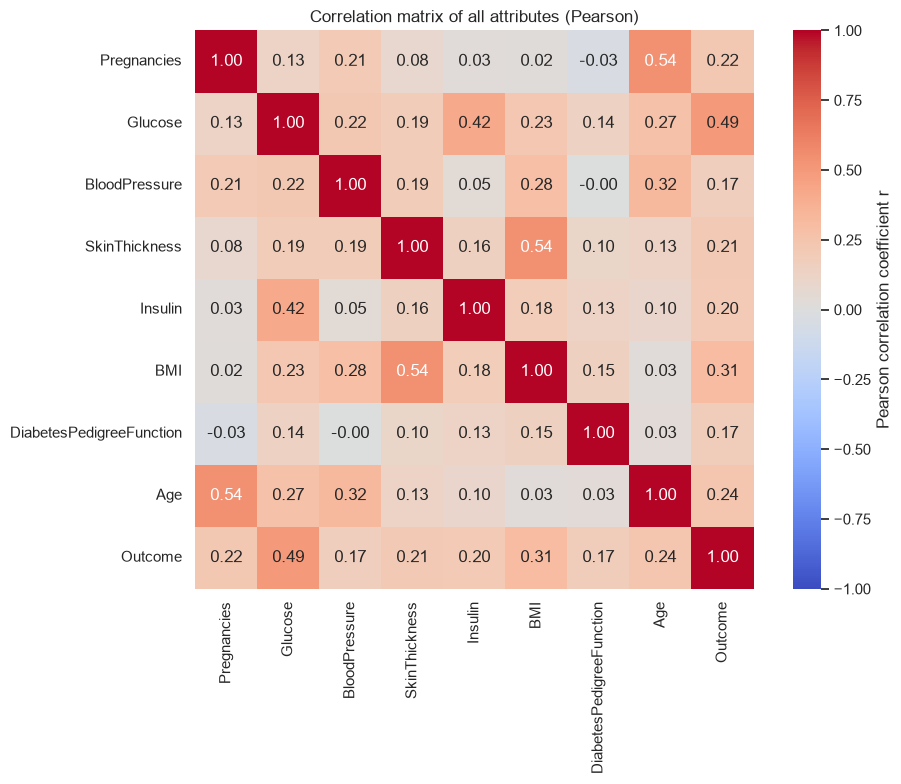

Correlation with Outcome:
Glucose                     0.493
BMI                         0.312
Age                         0.238
Pregnancies                 0.222
SkinThickness               0.215
Insulin                     0.204
DiabetesPedigreeFunction    0.174
BloodPressure               0.166
Name: Outcome, dtype: float64

Strongest pairs of attributes:
Pregnancies    Age        0.544
SkinThickness  BMI        0.543
Glucose        Insulin    0.419
dtype: float64


In [21]:
# Pearson correlation between every pair of columns (AgeBand excluded: not numeric)
corr = df_median[list(features) + ["Outcome"]].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
# annot=True writes the value in each cell; coolwarm: blue = negative, red = positive;
# vmin/vmax fix the colour scale to [-1, 1]
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Pearson correlation coefficient r"})
ax.set_title("Correlation matrix of all attributes (Pearson)")
plt.tight_layout()
plt.show()

# 1) Correlation of each attribute with Outcome, sorted
print("Correlation with Outcome:")
print(corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

# 2) Strongest pairs of attributes: keep the upper triangle (each pair once),
#    turn it into a list of pairs, remove pairs involving Outcome, keep the top 3
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("\nStrongest pairs of attributes:")
print(pairs.drop(labels="Outcome", level=1).sort_values(ascending=False).head(3).round(3))

**Interpretation.**
- **Most correlated with Outcome:** **Glucose** (r = 0.49), then BMI (0.31) and Age (0.24). All correlations with Outcome are positive.
- **Most correlated pair of attributes:** **Pregnancies–Age** (r = 0.54), almost tied with **SkinThickness–BMI** (r = 0.54), then Glucose–Insulin (0.42). No pair exceeds 0.8, so there is no serious redundancy between attributes.

**Does correlation imply causation? No.** Pregnancies and Age are correlated only because both increase with time. A correlation can come from a common cause (confounder), reverse causality or chance; only a controlled experiment or a causal analysis can establish causation.

## Question 16 — Pair plot
- **(a) Chart:** pair plot (scatter-plot matrix) of Glucose, BMI, Age, Insulin and DiabetesPedigreeFunction, coloured by Outcome
- **(b) Task:** relationships among several variables + distributions
- **(c) Why:** it combines all pairwise scatter plots and per-class distributions in one figure, whereas the heatmap gives only one number per pair and hides non-linear patterns and class separation.

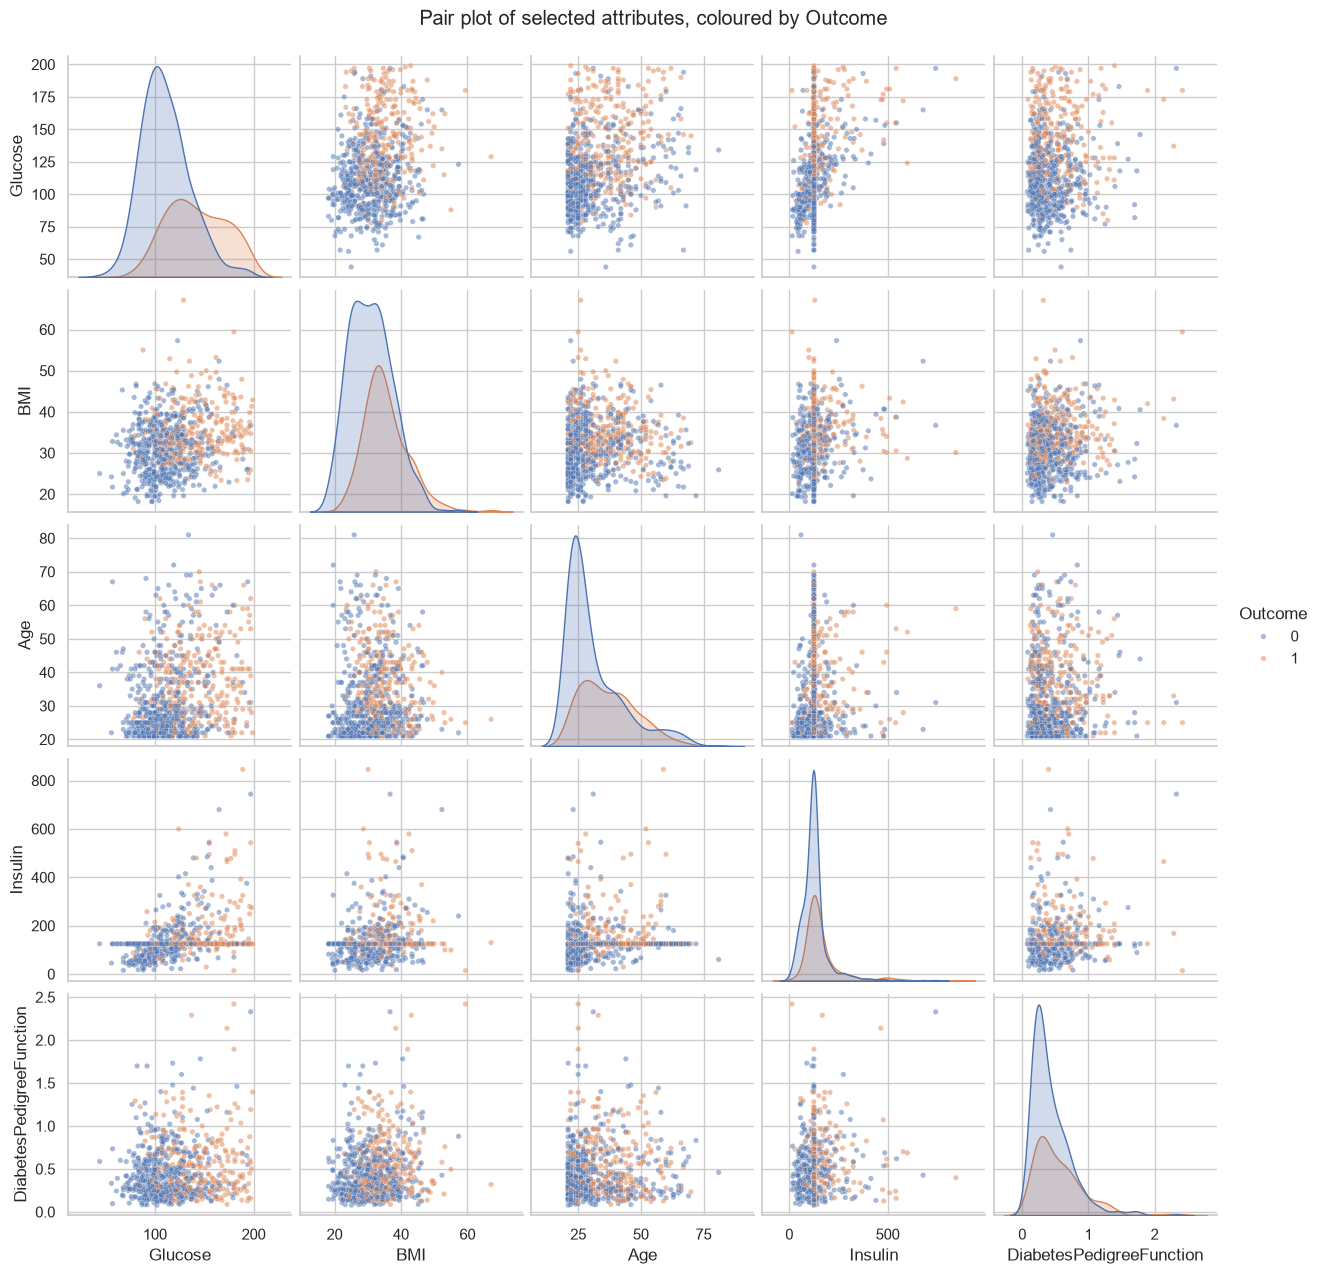

In [22]:
cols16 = ["Glucose", "BMI", "Age", "Insulin", "DiabetesPedigreeFunction", "Outcome"]
# Off-diagonal: scatter plot of every pair; diagonal (diag_kind="kde"): density of each attribute per class
pp = sns.pairplot(df_median[cols16], hue="Outcome", palette=colors, diag_kind="kde",
                  plot_kws={"alpha": 0.5, "s": 15})     # s = point size
pp.figure.suptitle("Pair plot of selected attributes, coloured by Outcome", y=1.02)
plt.show()

**Interpretation.**
- **Diagonal panels:** the distribution (density) of each single attribute, one curve per class. They show which attribute separates the classes on its own; Glucose's two curves are the most shifted.
- **Off-diagonal panels:** scatter plots of each pair of attributes, coloured by class. They show the relationship between two attributes and how well the pair separates the classes.
- **Best pair:** **Glucose–BMI** (also Glucose–Age). Diabetic points concentrate in the high-glucose / high-BMI corner. Every pair involving Glucose separates better than pairs without it; Insulin and DPF add little.

## Question 17 — Faceting by age band
- **(a) Chart:** faceted scatter plots of Glucose vs BMI, one panel per age band, coloured by Outcome
- **(b) Task:** relationship conditioned on a third variable (age)
- **(c) Why:** encoding age as point size or shape in a single scatter plot would be unreadable; facets keep each panel simple, with the same axes so they are directly comparable.

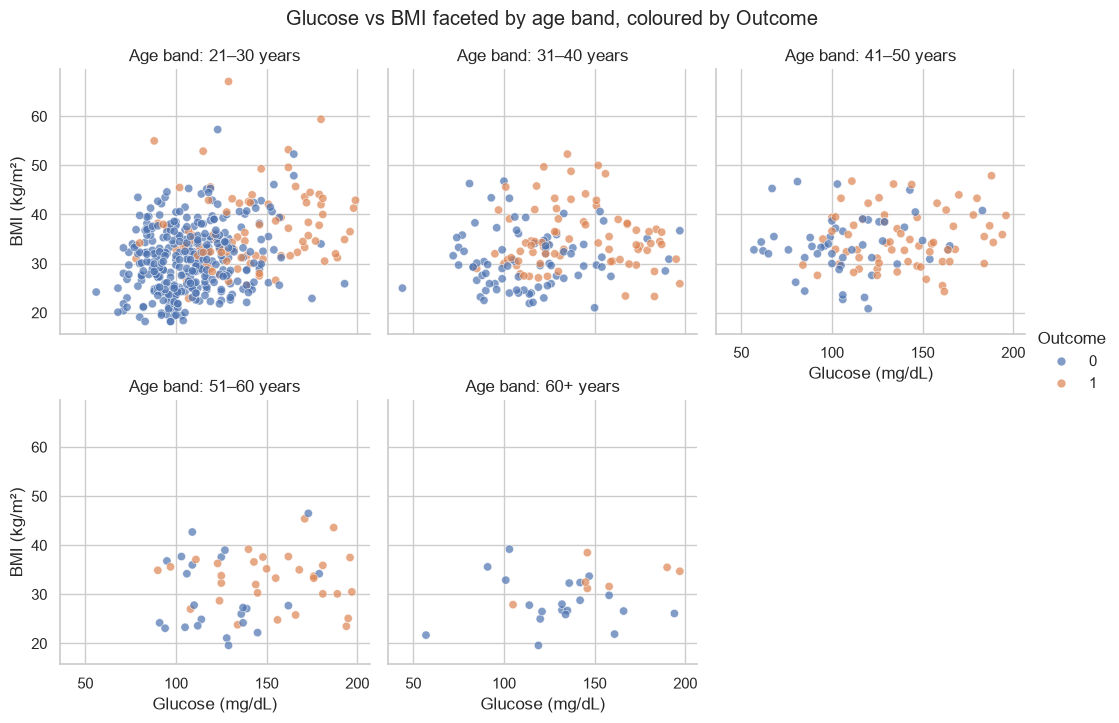

In [23]:
# col="AgeBand" → one panel per age band (faceting);
# col_wrap=3 → at most 3 panels per row; all panels share the same axes
g17 = sns.relplot(data=df_median, x="Glucose", y="BMI", hue="Outcome", col="AgeBand",
                  col_wrap=3, palette=colors, alpha=0.7, height=3.5)
g17.set_axis_labels("Glucose (mg/dL)", "BMI (kg/m²)")
g17.set_titles("Age band: {col_name} years")    # {col_name} is replaced by the band name
g17.figure.suptitle("Glucose vs BMI faceted by age band, coloured by Outcome", y=1.03)
plt.show()

**Interpretation.** Faceting reveals the effect of **age**, hidden in the single scatter plot of Q12. In the 21–30 panel most points are non-diabetic, even at moderately high glucose, while in the 31–60 panels diabetic points are far more frequent, including at lower glucose levels. The number of patients also drops sharply with age (417 in 21–30, only 27 in 60+). The Glucose/BMI risk is therefore **age-dependent**, an interaction that the single scatter plot mixed together.

## Question 18 — Chart critique

| Chart | What is wrong | Better alternative |
|---|---|---|
| **(a)** 3D pie chart of Outcome | Perspective distorts the slices (front slices look bigger); angles are already hard to compare; 3D adds no information. | **Bar chart** of class counts (Q3). |
| **(b)** Line chart of mean BMI per patient ID | Patient ID is an arbitrary identifier, not an ordered variable: the line invents a trend that does not exist, and "mean per patient" is just one value per patient. | **Histogram** or **box plot** of BMI, or box plot of BMI by Outcome. |
| **(c)** Bar chart of Glucose for all 768 patients | 768 thin bars in an arbitrary order: unreadable, and it shows individual values instead of the distribution. | **Histogram** (or KDE / box plot) of Glucose, possibly split by Outcome. |
| **(d)** Histogram with only 3 bins | Over-smoothing: shape, skewness, peaks and outliers disappear. | Histogram with a reasonable number of bins (~15–30, Freedman–Diaconis or Sturges rule), or a KDE. |

# Part 4 — Decision Trees and Ensemble Models

## Train / test split
Each dataset is split into **80 % training / 20 % test**, stratified on `Outcome` (both sets keep the 65/35 class ratio), with `random_state=42`. `df_median` and `df_knn` share the same row indices, so **the same patients** are in the test set for every model and every imputation, which makes the comparison fair.

In [24]:
def split(data):
    """Split a dataset into train (80 %) and test (20 %) sets."""
    X = data[features]           # inputs: the 8 attributes (AgeBand is NOT included)
    y = data["Outcome"]          # target
    # stratify=y keeps the class ratio; random_state fixes the shuffle → identical split every time
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

X_train, X_test, y_train, y_test = split(df_median)       # median-imputed data
Xk_train, Xk_test, yk_train, yk_test = split(df_knn)      # KNN-imputed data

print("Train:", X_train.shape, "| Test:", X_test.shape)   # (614, 8) | (154, 8)
print("Diabetic share — train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))
print("Same patients in both splits:", (X_train.index == Xk_train.index).all())

Train: (614, 8) | Test: (154, 8)
Diabetic share — train: 0.349 | test: 0.351
Same patients in both splits: True


## Question 19 — Decision tree and encoding

**Which attributes need encoding?** **None** of the 8 features:
- They are all numeric (int or float), and a decision tree splits on numeric thresholds ("Glucose ≤ 154.5"). It does not even need scaling.
- Encoding (`LabelEncoder`, one-hot…) is only required for **text or categorical** columns.
- The target `Outcome` is already encoded as 0/1; `LabelEncoder` is applied below only to show it changes nothing.
- The only categorical column, `AgeBand` (created in Q13), is excluded from the features.

In [25]:
print(df_median[features].dtypes)   # all int/float → nothing to encode

# LabelEncoder turns text labels into integers 0, 1, ...; Outcome is already 0/1
le = LabelEncoder()
y_encoded = le.fit_transform(y_train)
print("Classes found by LabelEncoder:", le.classes_, "→ already 0/1, nothing changes")

# Tree with no limits: it keeps splitting until every leaf is pure
tree_full = DecisionTreeClassifier(random_state=RS)
tree_full.fit(X_train, y_train)                     # learn the splits from the training data
print(f"Depth = {tree_full.get_depth()} | leaves = {tree_full.get_n_leaves()}")
# .score() returns accuracy; a big train/test gap means overfitting
print(f"Train accuracy = {tree_full.score(X_train, y_train):.3f} | "
      f"Test accuracy = {tree_full.score(X_test, y_test):.3f}")

Pregnancies                   int64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
dtype: object
Classes found by LabelEncoder: [0 1] → already 0/1, nothing changes
Depth = 14 | leaves = 111
Train accuracy = 1.000 | Test accuracy = 0.682


**Interpretation.** The unconstrained tree grows to depth 14 with 111 leaves. It reaches 100 % training accuracy but only 68.2 % on the test set: it has memorised the training patients (**overfitting**). Its complexity is controlled in Q23.

## Question 20 — Measuring impurity: Gini index and entropy

For a node where the classes have proportions p₀ and p₁:

| Measure | Formula | Meaning | Pure node | Maximum (2 classes) |
|---|---|---|---|---|
| **Gini index** | Gini = 1 − Σ pᵢ² | Probability of misclassifying a random sample labelled according to the node's class distribution | 0 | 0.5 |
| **Entropy** | H = − Σ pᵢ log₂ pᵢ | Average information (bits) needed to identify the class | 0 | 1 |

**Information gain** of a split = H(parent) − Σ (nₖ / n) · H(childₖ). The tree chooses the split with the largest gain (or largest Gini decrease).

### Hand computation for the root node
Training set: **614 patients, 400 non-diabetic, 214 diabetic** → p₀ = 400/614 = 0.6515, p₁ = 214/614 = 0.3485

- **Gini** = 1 − 0.6515² − 0.3485² = 1 − 0.4244 − 0.1215 = **0.454**
- **Entropy** = −0.6515 × log₂(0.6515) − 0.3485 × log₂(0.3485) = 0.6515 × 0.6182 + 0.3485 × 1.5207 = **0.933 bits**

### First split: **Glucose ≤ 154.5 mg/dL** (same with Gini and entropy)
| Child | Patients | Diabetic | p₁ | Entropy |
|---|---|---|---|---|
| Left (Glucose ≤ 154.5) | 515 | 131 | 0.254 | 0.818 |
| Right (Glucose > 154.5) | 99 | 83 | 0.838 | 0.638 |

- Weighted child entropy = (515/614) × 0.818 + (99/614) × 0.638 = 0.789
- **Information gain = 0.933 − 0.789 = 0.144 bits** (Gini decrease = 0.092)

In [26]:
# ---- Verify the hand computation ----
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()   # patients per class at the root
N = n0 + n1
p0, p1 = n0 / N, n1 / N                                # class proportions
gini_root = 1 - p0**2 - p1**2                          # Gini = 1 - Σ p²
ent_root = -(p0 * np.log2(p0) + p1 * np.log2(p1))      # Entropy = -Σ p·log2(p)
print(f"Root: {n0} non-diabetic, {n1} diabetic | Gini = {gini_root:.4f} | Entropy = {ent_root:.4f}")

# Impurity of any node (y = the 0/1 labels of the patients in that node)
def gini(y):
    p = y.mean()                                       # proportion of diabetics
    return 1 - p**2 - (1 - p)**2
def entropy(y):
    p = y.mean()
    return -sum(q * np.log2(q) for q in [p, 1 - p] if q > 0)   # skip q = 0 (log2(0) undefined)

# ---- Read the first split chosen by the tree (node 0 = root) ----
root_feat = features[tree_full.tree_.feature[0]]     # attribute used at the root
thr = tree_full.tree_.threshold[0]                   # its threshold
left = y_train[X_train[root_feat] <= thr]            # patients going left
right = y_train[X_train[root_feat] > thr]            # patients going right

# Weighted impurity of the children (weight = share of patients in each child)
w_ent = len(left) / N * entropy(left) + len(right) / N * entropy(right)
w_gini = len(left) / N * gini(left) + len(right) / N * gini(right)

print(f"First split: {root_feat} <= {thr}")
print(f"Left: {len(left)} patients ({left.sum()} diabetic) | Right: {len(right)} patients ({right.sum()} diabetic)")
print(f"Information gain = {ent_root - w_ent:.4f} | Gini decrease = {gini_root - w_gini:.4f}")

Root: 400 non-diabetic, 214 diabetic | Gini = 0.4541 | Entropy = 0.9328
First split: Glucose <= 154.5
Left: 515 patients (131 diabetic) | Right: 99 patients (83 diabetic)
Information gain = 0.1436 | Gini decrease = 0.0923


## Question 21 — Decision boundaries of a tree on two attributes
- **(a) Chart:** decision-boundary map (coloured regions = predicted class) with the training patients on top
- **(b) Task:** relationship (classification regions in the Glucose–BMI plane)
- **(c) Why:** it shows directly how the tree cuts the feature space, which a tree diagram does not show geometrically.

A tree of depth 4 trained on Glucose and BMI only is used so the regions stay readable.

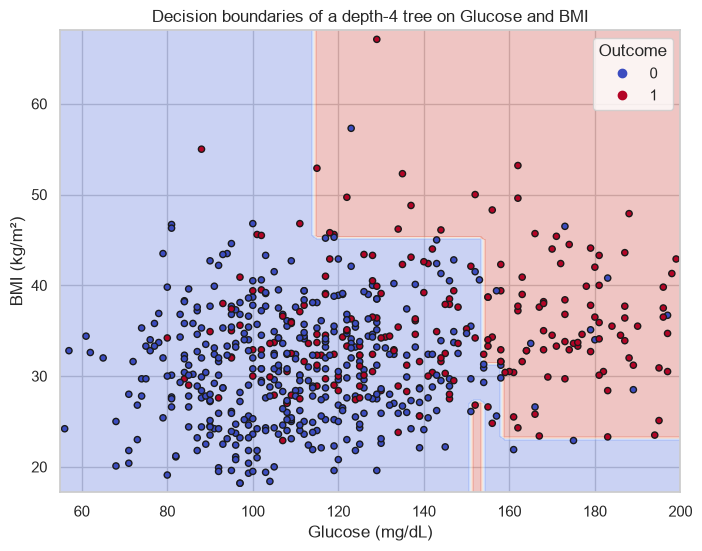

Test accuracy with only 2 attributes: 0.695


In [27]:
X2_train = X_train[["Glucose", "BMI"]]     # only 2 attributes → can be drawn in 2D
tree2 = DecisionTreeClassifier(max_depth=4, random_state=RS).fit(X2_train, y_train)

fig, ax = plt.subplots(figsize=(8, 6))
# Background colour = class predicted by the tree at every (Glucose, BMI) point
DecisionBoundaryDisplay.from_estimator(tree2, X2_train, response_method="predict",
                                       cmap="coolwarm", alpha=0.3, ax=ax)
# Real training patients on top, coloured by their true class
sc = ax.scatter(X2_train["Glucose"], X2_train["BMI"], c=y_train, cmap="coolwarm",
                edgecolor="k", s=20)
ax.legend(*sc.legend_elements(), title="Outcome")    # legend built from the point colours
ax.set_title("Decision boundaries of a depth-4 tree on Glucose and BMI")
ax.set_xlabel("Glucose (mg/dL)")
ax.set_ylabel("BMI (kg/m²)")
plt.show()
print("Test accuracy with only 2 attributes:", round(tree2.score(X_test[["Glucose", "BMI"]], y_test), 3))

**Interpretation.** The tree divides the plane into **axis-parallel rectangles**, because each node tests one attribute against a threshold. The main vertical cut is on Glucose (~155 mg/dL), and BMI thresholds then refine each side (low BMI → non-diabetic even with moderately high glucose). The staircase boundary cannot follow a diagonal frontier, and both colours remain inside each region: with only these two attributes the test accuracy is about 69 %.

## Question 22 — Visualising the decision tree
A tree of depth 3 is displayed, because the full depth-14 tree is unreadable. Each node shows the test, the impurity, the number of samples, the class counts and the majority class (colour = class, intensity = purity).

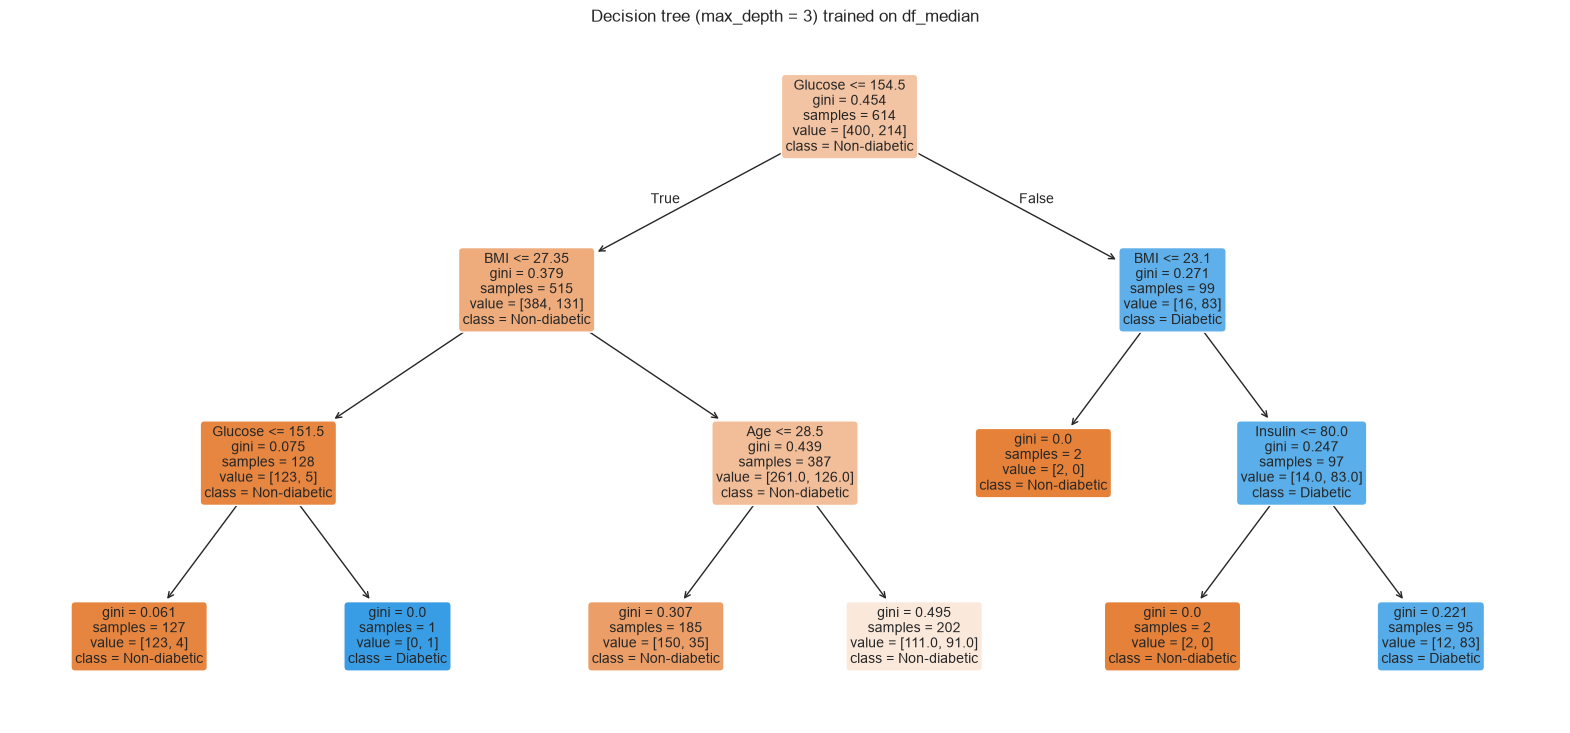

|--- Glucose <= 154.50
|   |--- BMI <= 27.35
|   |   |--- Glucose <= 151.50
|   |   |   |--- weights: [123.00, 4.00] class: 0
|   |   |--- Glucose >  151.50
|   |   |   |--- weights: [0.00, 1.00] class: 1
|   |--- BMI >  27.35
|   |   |--- Age <= 28.50
|   |   |   |--- weights: [150.00, 35.00] class: 0
|   |   |--- Age >  28.50
|   |   |   |--- weights: [111.00, 91.00] class: 0
|--- Glucose >  154.50
|   |--- BMI <= 23.10
|   |   |--- weights: [2.00, 0.00] class: 0
|   |--- BMI >  23.10
|   |   |--- Insulin <= 80.00
|   |   |   |--- weights: [2.00, 0.00] class: 0
|   |   |--- Insulin >  80.00
|   |   |   |--- weights: [12.00, 83.00] class: 1



In [28]:
# Small tree (depth 3) so the drawing stays readable
tree3 = DecisionTreeClassifier(max_depth=3, random_state=RS).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(20, 9))
# filled=True colours each node by its majority class (darker = purer)
plot_tree(tree3, feature_names=list(features), class_names=["Non-diabetic", "Diabetic"],
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title("Decision tree (max_depth = 3) trained on df_median")
plt.show()

# Same tree as indented text, the easiest way to read the IF ... THEN rules.
# show_weights=True prints [non-diabetic, diabetic] counts in each leaf
print(export_text(tree3, feature_names=list(features), show_weights=True))

### Interactive widget
A slider changes `max_depth` and redraws the tree with its test accuracy (requires `ipywidgets`, available in Jupyter Notebook/Lab).

In [29]:
from ipywidgets import interact, IntSlider

# @interact creates a slider; each time it moves, show_tree runs again with the new depth
@interact(depth=IntSlider(min=1, max=6, value=3, description="max_depth"))
def show_tree(depth):
    m = DecisionTreeClassifier(max_depth=depth, random_state=RS).fit(X_train, y_train)
    # figure size grows with depth so deep trees stay readable (capped at 30 inches wide)
    fig, ax = plt.subplots(figsize=(min(4 * 2**depth, 30), 2.5 * depth + 3))
    plot_tree(m, feature_names=list(features), class_names=["Non-diabetic", "Diabetic"],
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"Decision tree, max_depth = {depth} — test accuracy = {m.score(X_test, y_test):.3f}")
    plt.show()

interactive(children=(IntSlider(value=3, description='max_depth', max=6, min=1), Output()), _dom_classes=('wid…

## Question 23 — Reducing overfitting
**Step 1: effect of depth.**
- **(a) Chart:** line chart of training and test accuracy against `max_depth`
- **(b) Task:** trend over an ordered variable
- **(c) Why:** depth is ordered and numeric, and two lines show exactly where the curves diverge.

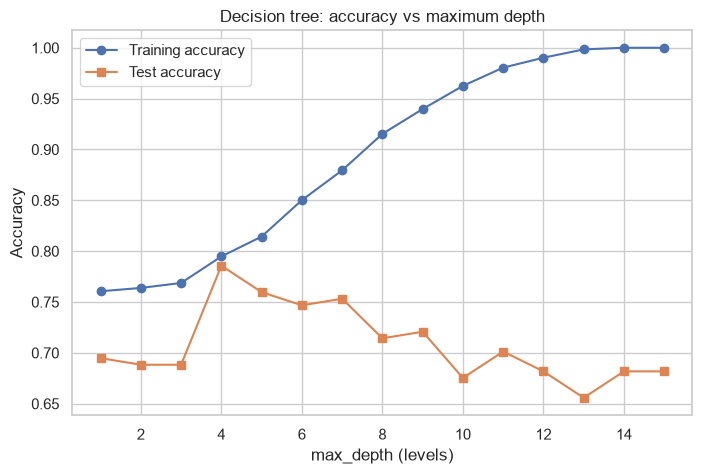

In [32]:
depths = range(1, 16)                 # try depths 1 to 15
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RS).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))   # accuracy on data the tree has seen
    test_acc.append(m.score(X_test, y_test))      # accuracy on unseen data

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(depths, train_acc, marker="o", label="Training accuracy")
ax.plot(depths, test_acc, marker="s", label="Test accuracy")
ax.set_title("Decision tree: accuracy vs maximum depth")
ax.set_xlabel("max_depth (levels)")
ax.set_ylabel("Accuracy")
ax.legend()
plt.show()

**Step 2: tuning `max_depth`, `min_samples_leaf` and `ccp_alpha` together.**
We use a grid search with **5-fold stratified cross-validation on the training set only**: the test set must never be used to choose hyper-parameters, otherwise its score becomes optimistic. The scoring metric is **F1**, because of the class imbalance.
- `max_depth`: maximum number of levels.
- `min_samples_leaf`: minimum number of patients in a leaf (prevents tiny, noisy leaves).
- `ccp_alpha`: cost-complexity pruning strength (removes branches that add little).

In [33]:
# 5-fold CV: the training set is cut into 5 parts, each used once for validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

# All combinations to try (7 × 5 × 5 = 175 trees, each trained 5 times)
param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, None],
              "min_samples_leaf": [1, 5, 10, 20, 30],
              "ccp_alpha": [0.0, 0.001, 0.003, 0.005, 0.01]}

# scoring="f1" because the classes are imbalanced; n_jobs=-1 uses all CPU cores
grid = GridSearchCV(DecisionTreeClassifier(random_state=RS), param_grid,
                    cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

best_tree = grid.best_estimator_      # best tree, refitted on the whole training set
print("Best parameters:", grid.best_params_, "| CV F1 =", round(grid.best_score_, 3))
print("Test accuracy of the tuned tree:", round(best_tree.score(X_test, y_test), 3))

Best parameters: {'ccp_alpha': 0.0, 'max_depth': 4, 'min_samples_leaf': 30} | CV F1 = 0.62
Test accuracy of the tuned tree: 0.792


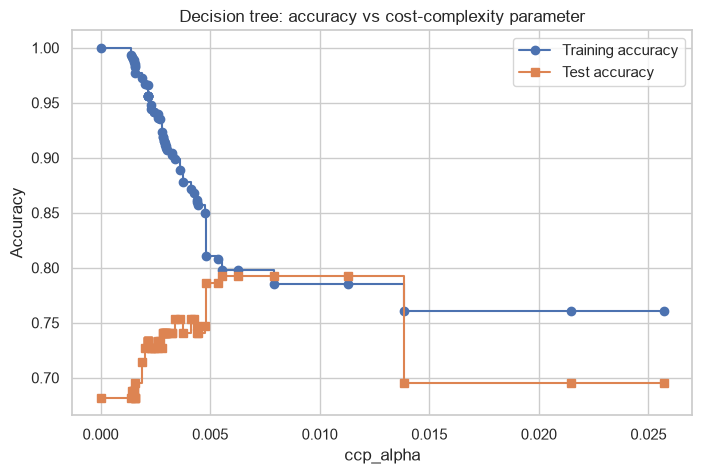

In [34]:
# Cost-complexity pruning path: every alpha at which a branch would be pruned
path = DecisionTreeClassifier(random_state=RS).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]   # drop the last alpha (it prunes everything → single node)

tr_a, te_a = [], []
for a in alphas:                # larger alpha → more pruning → simpler tree
    m = DecisionTreeClassifier(random_state=RS, ccp_alpha=a).fit(X_train, y_train)
    tr_a.append(m.score(X_train, y_train))
    te_a.append(m.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(8, 5))
# steps-post: accuracy is constant between two alphas, so we draw steps
ax.plot(alphas, tr_a, marker="o", drawstyle="steps-post", label="Training accuracy")
ax.plot(alphas, te_a, marker="s", drawstyle="steps-post", label="Test accuracy")
ax.set_title("Decision tree: accuracy vs cost-complexity parameter")
ax.set_xlabel("ccp_alpha")
ax.set_ylabel("Accuracy")
ax.legend()
plt.show()

**Interpretation.**
- Training accuracy rises steadily with depth until it reaches 100 % (depth ≥ 14).
- Test accuracy peaks at **depth 4 (78.6 %)** and then decreases (≈ 68 % at depth 14).
- **The tree starts to overfit after depth 4:** deeper trees learn noise specific to the training patients.
- The grid search confirms it: best parameters `max_depth = 4`, `min_samples_leaf = 30`, `ccp_alpha = 0` (test accuracy 79.2 %).
- Increasing `ccp_alpha` has the same effect as limiting depth: it prunes weak branches, lowering training accuracy and closing the gap with test accuracy.

## Question 24 — Bagging

**Bagging = Bootstrap AGGregatING**
1. **Bootstrap sampling:** draw B training sets of the same size by sampling *with replacement*. Each contains about 63 % distinct patients, some repeated.
2. **Training:** fit one deep decision tree on each sample → B different trees.
3. **Aggregation by vote:** for a new patient, every tree votes and the majority class is the prediction.

**Why it reduces variance:** a deep tree has low bias but high variance (a small change in the data produces a very different tree). Averaging B models whose errors are not perfectly correlated reduces variance (for B independent models of variance σ², the average has variance σ²/B) without increasing bias. The ~37 % of patients left out of each bootstrap (**out-of-bag**) provide a free validation estimate.

In [35]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RS),  # base model: a full (deep) tree
    n_estimators=200,       # 200 trees
    bootstrap=True,         # each tree gets a sample drawn WITH replacement
    oob_score=True,         # evaluate on the patients each tree did not see (out-of-bag)
    random_state=RS,
    n_jobs=-1)              # train the trees in parallel
bag.fit(X_train, y_train)   # prediction = majority vote of the 200 trees

print(f"Out-of-bag accuracy = {bag.oob_score_:.3f}")
print(f"Train accuracy = {bag.score(X_train, y_train):.3f} | Test accuracy = {bag.score(X_test, y_test):.3f}")

Out-of-bag accuracy = 0.754
Train accuracy = 1.000 | Test accuracy = 0.734


**Interpretation.** With 200 bootstrapped trees, the out-of-bag accuracy is 75.4 % and the test accuracy 73.4 %, better than a single unpruned tree (68.2 %): averaging removed a large part of the variance. Training accuracy stays at 100 % because each tree is fully grown. Bagging reduces variance, not the complexity of the individual trees.

## Question 25 — XGBoost (boosting)

**Boosting concept:** trees are built **sequentially**. Each new shallow tree is trained to correct the errors of the current ensemble (in gradient boosting it fits the gradient of the loss, i.e. the residual errors), and its prediction is added with a small weight (the learning rate). XGBoost adds L1/L2 regularisation, second-order gradients, row/column subsampling and fast parallel split finding.

| | **Bagging** | **Boosting** |
|---|---|---|
| Training | Parallel, independent trees | Sequential, each tree depends on the previous ones |
| Base learners | Deep trees (low bias, high variance) | Shallow trees (high bias, low variance) |
| Main effect | Reduces **variance** | Reduces **bias** (and variance through regularisation) |
| Focus | Uniform bootstrap samples | Hard / misclassified patients |
| Combination | Equal-weight vote | Weighted sum (learning rate) |

In [36]:
xgb = XGBClassifier(
    n_estimators=300,        # 300 trees added one after another
    learning_rate=0.05,      # each new tree corrects only a small part of the error → stable learning
    max_depth=3,             # shallow trees (weak learners)
    subsample=0.8,           # each tree sees a random 80 % of the patients
    colsample_bytree=0.8,    # ... and a random 80 % of the attributes (less overfitting)
    eval_metric="logloss",   # loss minimised for binary classification
    random_state=RS)
xgb.fit(X_train, y_train)
print(f"Train accuracy = {xgb.score(X_train, y_train):.3f} | Test accuracy = {xgb.score(X_test, y_test):.3f}")

Train accuracy = 0.930 | Test accuracy = 0.734


**Feature importances**
- **(a) Chart:** sorted horizontal bar chart
- **(b) Task:** comparison (ranking)
- **(c) Why:** horizontal bars keep long attribute names readable, and sorting makes the ranking immediate; a pie chart could not show a ranking of 8 values clearly.

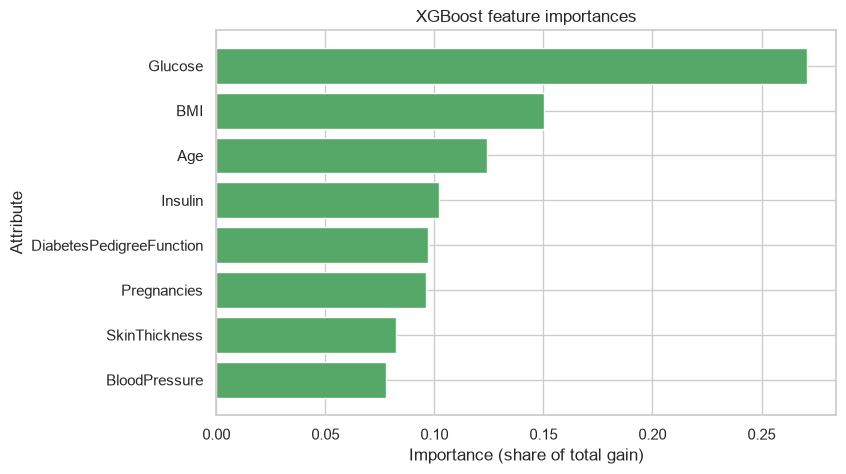

Glucose                     0.271
BMI                         0.150
Age                         0.124
Insulin                     0.102
DiabetesPedigreeFunction    0.097
Pregnancies                 0.096
SkinThickness               0.082
BloodPressure               0.078
dtype: float32

In [37]:
# Importance = share of the total gain brought by the splits on each attribute
importances = pd.Series(xgb.feature_importances_, index=features).sort_values()   # ascending → largest on top

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importances.index, importances.values, color="#55A868")   # barh = horizontal bars
ax.set_title("XGBoost feature importances")
ax.set_xlabel("Importance (share of total gain)")
ax.set_ylabel("Attribute")
plt.show()
importances.sort_values(ascending=False).round(3)

**Interpretation.** XGBoost reaches 76.6 % test accuracy. **Glucose** dominates the importances (≈ 27 % of the total gain), about twice the next attributes, **BMI** (14 %) and **Age** (12 %). BloodPressure and SkinThickness are the least useful (≈ 8 % each). This matches the correlation matrix, the box plots and the root split of the decision tree: every method designates Glucose, BMI and Age as the key predictors.

# Part 5 — Evaluation and Comparison

## Question 26 — Evaluation of the three models (df_median)
Each model is evaluated on the same test set (154 patients) with:
- **Confusion matrix:** shown as a heatmap of the 2×2 counts. **Task:** comparison of correct and incorrect predictions per class. **Why a heatmap:** the colour intensity draws the eye to the largest cells.
- **Metrics:**

| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP + TN) / N | What share of all predictions is correct? |
| Precision | TP / (TP + FP) | Among patients predicted diabetic, how many really are? |
| Recall | TP / (TP + FN) | Among real diabetics, how many are detected? |
| F1-score | 2 · P · R / (P + R) | Balance between precision and recall |
| AUC | Area under the ROC curve | How well does the model rank diabetics above non-diabetics, at every threshold? |

(TP = true positives, TN = true negatives, FP = false positives, FN = false negatives; positive = diabetic.)

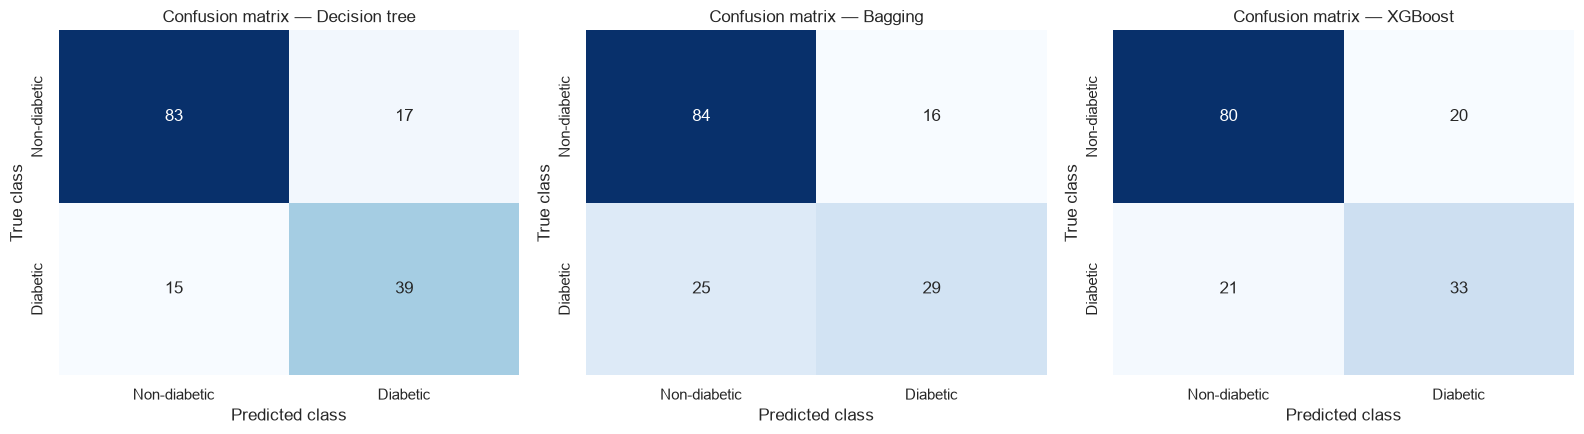

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Decision tree,0.792,0.696,0.722,0.709,0.815
Bagging,0.734,0.644,0.537,0.586,0.810
XGBoost,0.734,0.623,0.611,0.617,0.830


In [38]:
# The 3 final models in a dictionary, so we can loop over them
models = {"Decision tree": best_tree, "Bagging": bag, "XGBoost": xgb}

rows = []                                             # one dictionary of metrics per model
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))     # one confusion matrix per model
for ax, (name, m) in zip(axes, models.items()):
    y_pred = m.predict(X_test)                # predicted class (0/1), threshold 0.5
    y_prob = m.predict_proba(X_test)[:, 1]    # predicted probability of being diabetic (for AUC/ROC)

    # Confusion matrix: rows = true class, columns = predicted class → [[TN, FP], [FN, TP]]
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Non-diabetic", "Diabetic"], yticklabels=["Non-diabetic", "Diabetic"])
    ax.set_title(f"Confusion matrix — {name}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")

    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, y_pred),
                 "Precision": precision_score(y_test, y_pred),
                 "Recall": recall_score(y_test, y_pred),
                 "F1": f1_score(y_test, y_pred),
                 "AUC": roc_auc_score(y_test, y_prob)})
plt.tight_layout()
plt.show()

results = pd.DataFrame(rows).set_index("Model").round(3)   # list of dictionaries → table
results

**ROC curves**
- **(a) Chart:** ROC curves of all models on the same axes (line chart)
- **(b) Task:** comparison of the models' ability to rank patients, across all thresholds
- **(c) Why:** unlike the confusion matrix, ROC does not depend on the 0.5 threshold, and putting all curves on the same axes makes the comparison immediate.

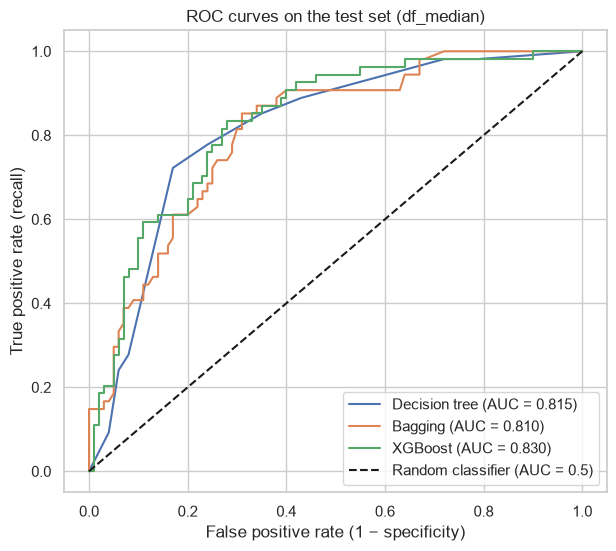

In [39]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in models.items():
    y_prob = m.predict_proba(X_test)[:, 1]
    # roc_curve tries every threshold and returns the false/true positive rates
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")
# Diagonal = random classifier; a good curve bends toward the top-left corner
ax.plot([0, 1], [0, 1], "k--", label="Random classifier (AUC = 0.5)")
ax.set_title("ROC curves on the test set (df_median)")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.show()

**Results (test set, 154 patients, df_median)**

| Model | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Decision tree (tuned) | **0.792** | **0.696** | **0.722** | **0.709** | 0.815 |
| Bagging | 0.734 | 0.644 | 0.537 | 0.586 | 0.810 |
| XGBoost | 0.766 | 0.673 | 0.648 | 0.660 | **0.831** |

**Interpretation.** On this split the tuned decision tree has the best accuracy and F1, while XGBoost has the best AUC, meaning it ranks patients by risk best across all thresholds. Bagging has the lowest recall: it misses almost half of the diabetics (25 of 54). All ROC curves lie well above the diagonal.

**Why accuracy alone is not enough on this dataset:**
- With 65 % non-diabetics, a model predicting "non-diabetic" for everyone reaches 65 % accuracy and is useless.
- Accuracy treats both errors equally, but in medicine a **false negative** (a missed diabetic) is much more costly than a false positive (an extra test).
- Recall, precision, F1 and AUC show how well the minority (diabetic) class is actually detected.

## Question 27 — Effect of the imputation method
Every model, with the same hyper-parameters, is retrained on `df_median` and on `df_knn`, using the same train/test split.
- **(a) Chart:** grouped bar chart (F1 and AUC; 3 models × 2 imputations)
- **(b) Task:** comparison
- **(c) Why:** bars side by side make the difference between the two imputations visible for each model, and two panels with the same scale (0–1) compare F1 and AUC.

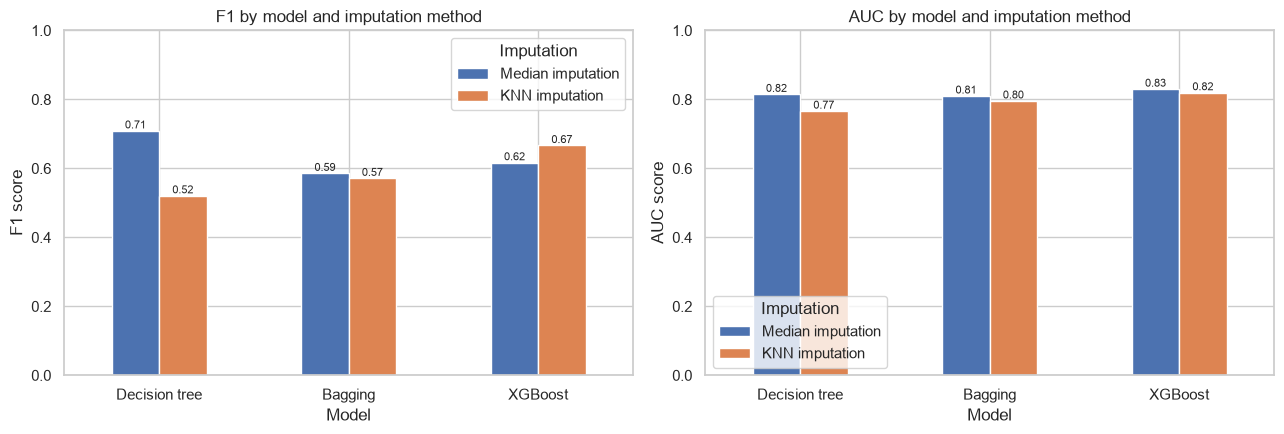

median           knn       
                  F1    AUC     F1    AUC
Decision tree  0.709  0.815  0.521  0.766
Bagging        0.586  0.810  0.571  0.796
XGBoost        0.617  0.830  0.667  0.820

In [40]:
def evaluate(Xtr, Xte, ytr, yte):
    """Retrain each model on the given data and return its test F1 and AUC."""
    out = {}
    for name, m in models.items():
        # clone() copies the hyper-parameters but not what was learned → fresh model
        mm = clone(m).fit(Xtr, ytr)
        out[name] = {"F1": f1_score(yte, mm.predict(Xte)),
                     "AUC": roc_auc_score(yte, mm.predict_proba(Xte)[:, 1])}
    return pd.DataFrame(out).T     # .T → one row per model

res_median = evaluate(X_train, X_test, y_train, y_test)        # median-imputed data
res_knn = evaluate(Xk_train, Xk_test, yk_train, yk_test)       # KNN-imputed data

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))              # left: F1, right: AUC
for ax, metric in zip(axes, ["F1", "AUC"]):
    # rows = models, columns = imputation → pandas draws grouped bars
    pd.DataFrame({"Median imputation": res_median[metric],
                  "KNN imputation": res_knn[metric]}).plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"{metric} by model and imputation method")
    ax.set_xlabel("Model")
    ax.set_ylabel(f"{metric} score")
    ax.set_ylim(0, 1)                             # same scale for both panels
    ax.legend(title="Imputation")
    for c in ax.containers:                       # each group of bars
        ax.bar_label(c, fmt="%.2f", fontsize=8)   # write the value on each bar
plt.tight_layout()
plt.show()

# Final comparison table
pd.concat({"median": res_median, "knn": res_knn}, axis=1).round(3)

**Results**

| Model | F1 (median) | AUC (median) | F1 (KNN) | AUC (KNN) |
|---|---|---|---|---|
| Decision tree | 0.709 | 0.815 | 0.521 | 0.766 |
| Bagging | 0.586 | 0.810 | 0.571 | 0.796 |
| XGBoost | 0.660 | 0.831 | 0.648 | 0.812 |

**Does the imputation change the ranking? Yes.**
- With median imputation, the decision tree has the best F1. With KNN imputation it drops to last (F1 = 0.52), and XGBoost becomes first on both metrics.
- The ensembles barely change (≤ 0.02), while the single tree changes a lot: a single tree is unstable (high variance), and its hyper-parameters were tuned on `df_median`.
- XGBoost has the best AUC with both imputations.
- KNN imputation preserved the distributions better (Q6) but did not improve the scores here. With only 154 test patients, differences of 1–2 points are within noise.

## Question 28 — Conclusion: which method performs best?

| Criterion | Decision tree | Bagging | XGBoost |
|---|---|---|---|
| Accuracy (median) | **0.79** | 0.73 | 0.77 |
| F1 (median / KNN) | **0.71** / 0.52 | 0.59 / 0.57 | 0.66 / **0.65** |
| AUC (median / KNN) | 0.82 / 0.77 | 0.81 / 0.80 | **0.83 / 0.81** |
| Interpretability | **High**: readable IF–THEN rules | Low: 200 trees | Low: needs feature importances / SHAP |
| Training cost | **Very low**: one tree | Medium: 200 trees, parallel | Medium: sequential but highly optimised |
| Stability | Low: sensitive to data and imputation | High | High |

**Best method overall: XGBoost.** It has the highest AUC under both imputations and the most stable F1, so it gives the most reliable ranking of patients by risk.

- The **tuned decision tree** can match it on one split and is far more interpretable and cheaper, but its performance collapses when the data change slightly. It is an excellent *explanatory* model, not the most reliable predictor.
- **Bagging** reduces the tree's variance, but with fully grown trees and the default threshold it misses too many diabetics (lowest recall).

**Limits:** all conclusions rest on a single test set of 154 patients. Repeated cross-validation and tuning the decision threshold to favour recall would give a more robust comparison.

## Question 29 — Presenting the findings to a doctor with three charts

| Order | Chart | Single message | Why this chart |
|---|---|---|---|
| 1 | **Density of Glucose by Outcome** (Q11) | "Glucose is the strongest sign: above ≈ 140–145 mg/dL, most patients are diabetic." | The key finding, in the doctor's own unit, close to a familiar clinical threshold. |
| 2 | **Percentage of diabetics per age band** (Q13) | "The risk more than doubles after 30 and exceeds 50 % after 40." | A simple percentage per age group is directly usable for screening. |
| 3 | **Confusion matrix of the best model** (Q26) | "Out of 54 diabetic patients, the model detects X and misses Y." | A doctor needs to know how reliable the tool is and what it misses, in patient counts rather than abstract scores. |

**Order:** from the main risk factor, to the second factor, to what the model can do with them, which builds a clear story.
**Alternative for chart 3:** the depth-3 decision tree (Q22), whose IF–THEN rules resemble clinical guidelines.
**Excluded:** the pair plot, correlation heatmap and ROC curves. They are accurate, but too technical for a three-chart clinical message.

# General conclusion
- **Data quality:** 5 attributes contained impossible zeros (missing values), up to 49 % for Insulin. KNN imputation preserved the distributions better than median imputation.
- **Exploration:** every chart (box plots, KDE, correlation, pair plot, feature importances) points to the same key predictors: **Glucose**, then **BMI** and **Age**. The classes overlap strongly, so no simple rule separates them perfectly.
- **Modelling:** a single tree overfits beyond depth 4. Bagging reduces variance, and XGBoost gives the best and most stable AUC (≈ 0.83). Because the classes are imbalanced, the models must be judged on recall, F1 and AUC, not accuracy alone.
- **Chart choice matters:** the right chart answers a precise question (comparison, distribution, relationship, composition, trend), and the wrong one (3D pie, line over IDs, too few bins) hides or distorts the message.